In [ ]:
import pandas as pd

# Load dataset
df_bataineh = pd.read_csv("3-Bataineh dataset.csv")
df_bataineh.head()


,index,text,label,source,text_word_count,label_cat,source_int,processed_text
0,47,All the Love you do not see\n\nOn writing with...,0,medium,236,human,0,love see write heart hope photo joshua coleman...
1,85,"Reading, writing and displaying images\n\nBefo...",0,medium,386,human,0,read write display image anything computer vis...
2,255,Why I Think “Target Audience” Doesn’t Always M...,0,medium,323,human,0,think target audience always matter much first...
3,268,"All sorts of books are published every year, a...",0,medium,176,human,0,sort book publish every year sort bookbuyers l...
4,315,Finding The Right Question Not Answer\n\nWhen ...,0,medium,264,human,0,find right question answer face problem one fi...


Basic EDA (Optional but useful)

In [ ]:
df_bataineh['label_cat'].value_counts()
df_bataineh.describe()


,index,label,text_word_count,source_int
count,10000.000000,10000.000000,10000.000000,10000.000000
mean,171923.678100,0.500000,266.199900,1.434000
std,59703.274397,0.500025,123.808486,1.150555
min,47.000000,0.000000,51.000000,0.000000
25%,150305.750000,0.000000,155.750000,0.000000
50%,205451.500000,0.500000,275.500000,1.500000
75%,210022.500000,1.000000,385.000000,2.000000
max,214728.000000,1.000000,449.000000,3.000000


Statistical Significance Testing

In [ ]:
human_bat = df_bataineh[df_bataineh['label_cat'] == 'human']
ai_bat = df_bataineh[df_bataineh['label_cat'] == 'ai']


In [ ]:
df_bataineh['label_cat'].value_counts()


,count
label_cat,
human,5000
machine,5000


Feature Engineering + Apply on Bataineh

In [ ]:
import pandas as pd
import numpy as np
import string
import nltk
from nltk.corpus import stopwords
nltk.download('stopwords')

stop_words = set(stopwords.words('english'))

# Compute features
def compute_features(text):
    tokens = str(text).split()
    word_count = len(tokens)
    char_count = len(str(text))
    avg_word_len = np.mean([len(word) for word in tokens]) if tokens else 0
    upper_ratio = sum(1 for char in str(text) if char.isupper()) / len(str(text)) if len(str(text)) > 0 else 0
    punct_ratio = sum(1 for char in str(text) if char in string.punctuation) / len(str(text)) if len(str(text)) > 0 else 0
    stopword_ratio = sum(1 for word in tokens if word.lower() in stop_words) / word_count if word_count > 0 else 0
    lexical_diversity = len(set(tokens)) / word_count if word_count > 0 else 0
    return pd.Series([word_count, char_count, avg_word_len, upper_ratio, punct_ratio, stopword_ratio, lexical_diversity])

# Apply
df_bataineh[['word_count', 'char_count', 'avg_word_len', 'upper_ratio',
             'punct_ratio', 'stopword_ratio', 'lexical_diversity']] = df_bataineh['processed_text'].apply(compute_features)


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


In [ ]:
df_bataineh[[
    'word_count', 'char_count', 'avg_word_len', 'upper_ratio',
    'punct_ratio', 'stopword_ratio', 'lexical_diversity'
]].head()


,word_count,char_count,avg_word_len,upper_ratio,punct_ratio,stopword_ratio,lexical_diversity
0,125.0,867.0,5.944000,0.0,0.000000,0.0,0.832000
1,204.0,1332.0,5.534314,0.0,0.000751,0.0,0.583333
2,153.0,1019.0,5.666667,0.0,0.000000,0.0,0.601307
3,98.0,632.0,5.459184,0.0,0.000000,0.0,0.653061
4,155.0,1144.0,6.387097,0.0,0.000000,0.0,0.677419


Statistical Significance Tests (T-test & ANOVA)

In [ ]:
# ==== RESET: build X/y, split, and scale ====
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 1) Columns (edit y_col if your label name is different)
feature_names = [
    'word_count','char_count','avg_word_len','upper_ratio',
    'punct_ratio','stopword_ratio','lexical_diversity'
]
y_col = 'label'   # change if needed

# 2) X/y from your engineered dataset
X = df_bataineh[feature_names].astype(float)
y = df_bataineh[y_col].astype(int)
print("Label counts:\n", y.value_counts())

# 3) Train/test split (same seed as before so results are reproducible)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)

# 4) Scale using train statistics
scaler = StandardScaler()
X_train_scaled = pd.DataFrame(
    scaler.fit_transform(X_train), columns=feature_names, index=X_train.index
)
X_test_scaled = pd.DataFrame(
    scaler.transform(X_test), columns=feature_names, index=X_test.index
)

print("Shapes:", X_train_scaled.shape, X_test_scaled.shape)


Label counts:
 label
0    5000
1    5000
Name: count, dtype: int64
Shapes: (8000, 7) (2000, 7)


In [ ]:
# ==== DIAGNOSTICS (variance / uniqueness per class) ====
X_df = X_test  # or X_test_scaled; both are fine for the tests
y_aligned = pd.Series(y_test, index=X_df.index)

for f in feature_names:
    a = X_df.loc[y_aligned==0, f].dropna()   # 0 = Human (flip if your mapping differs)
    b = X_df.loc[y_aligned==1, f].dropna()   # 1 = AI
    print(f"{f:17s}  n0={len(a):4d} n1={len(b):4d}  "
          f"uniq0={a.nunique():4d} uniq1={b.nunique():4d}  "
          f"var0={a.var():.4g} var1={b.var():.4g}")


word_count         n0=1000 n1=1000  uniq0= 285 uniq1= 221  var0=5345 var1=4190
char_count         n0=1000 n1=1000  uniq0= 775 uniq1= 728  var0=3.252e+05 var1=1.955e+05
avg_word_len       n0=1000 n1=1000  uniq0= 960 uniq1= 943  var0=0.7584 var1=0.5058
upper_ratio        n0=1000 n1=1000  uniq0=   1 uniq1=   1  var0=0 var1=0
punct_ratio        n0=1000 n1=1000  uniq0=  42 uniq1=  14  var0=3.575e-06 var1=3.065e-05
stopword_ratio     n0=1000 n1=1000  uniq0=  83 uniq1=  96  var0=8.439e-06 var1=4.201e-05
lexical_diversity  n0=1000 n1=1000  uniq0= 864 uniq1= 826  var0=0.01137 var1=0.03102


In [ ]:
# ==== ROBUST TESTS (Welch t when OK, else Mann–Whitney) ====
from scipy import stats

def compare_feature(X_df, y_aligned, feature):
    a = X_df.loc[y_aligned==0, feature].dropna().to_numpy()  # Human
    b = X_df.loc[y_aligned==1, feature].dropna().to_numpy()  # AI
    out = {"feature": feature, "n_human": len(a), "n_ai": len(b)}

    # Welch t-test if both groups have >=10 samples and non-zero variance
    if len(a)>=10 and len(b)>=10 and np.var(a)>0 and np.var(b)>0:
        t, p = stats.ttest_ind(a, b, equal_var=False)
        d = (a.mean()-b.mean()) / np.sqrt((a.var(ddof=1)+b.var(ddof=1))/2)  # Cohen's d
        out.update(test="Welch t", p_value=p, effect=d, effect_name="Cohen_d")
    else:
        U, p = stats.mannwhitneyu(a, b, alternative="two-sided")
        delta = ((a[:,None] > b).mean() - (a[:,None] < b).mean())           # Cliff's δ
        out.update(test="Mann–Whitney U", p_value=p, effect=delta, effect_name="Cliffs_delta")
    return out

stats_tbl = pd.DataFrame([compare_feature(X_df, y_aligned, f) for f in feature_names]) \
              .sort_values("p_value")
stats_tbl


,feature,n_human,n_ai,test,p_value,effect,effect_name
2,avg_word_len,1000,1000,Welch t,5.172497e-39,0.597618,Cohen_d
1,char_count,1000,1000,Welch t,2.680144e-31,0.529991,Cohen_d
6,lexical_diversity,1000,1000,Welch t,3.352103e-27,0.491874,Cohen_d
0,word_count,1000,1000,Welch t,3.729250e-19,0.404170,Cohen_d
5,stopword_ratio,1000,1000,Welch t,5.697090e-04,-0.154453,Cohen_d
4,punct_ratio,1000,1000,Welch t,7.440166e-01,-0.014607,Cohen_d
3,upper_ratio,1000,1000,Mann–Whitney U,1.000000e+00,0.000000,Cliffs_delta


In [ ]:
# peek at the plausible label columns
for col in ['label','label_cat','source','source_int']:
    if col in df_bataineh.columns:
        print(f"\n{col} value counts:")
        print(df_bataineh[col].astype(str).str.strip().str.lower().value_counts(dropna=False).head(20))



label value counts:
label
0    5000
1    5000
Name: count, dtype: int64

label_cat value counts:
label_cat
human      5000
machine    5000
Name: count, dtype: int64

source value counts:
source
medium           3025
rotten_tomato    2635
wmt-16           2365
wikipedia        1975
Name: count, dtype: int64

source_int value counts:
source_int
0    3025
2    2635
3    2365
1    1975
Name: count, dtype: int64


In [ ]:
# (A) If you have text labels like "human"/"ai"
df_bataineh['label_num'] = (
    df_bataineh['label_cat']
      .astype(str).str.strip().str.lower()
      .map({'human':0, 'ai':1, 'gpt':1, 'chatgpt':1})
)

# (B) If 'source' tells you (e.g., contains 'ai' in the name)
df_bataineh['label_num'] = df_bataineh['source'].astype(str).str.contains('ai', case=False).astype(int)

# (C) If 'label' is already 0/1 but got corrupted, remake it from another column, then:
df_bataineh['label'] = df_bataineh['label_num']


In [ ]:
print("Label counts:", df_bataineh['label_num'].value_counts(dropna=False))


Label counts: label_num
0    10000
Name: count, dtype: int64


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import pandas as pd

feature_names = ['word_count','char_count','avg_word_len','upper_ratio',
                 'punct_ratio','stopword_ratio','lexical_diversity']

X = df_bataineh[feature_names].astype(float)
y = df_bataineh['label_num'].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)

scaler = StandardScaler()
X_test_scaled = pd.DataFrame(
    scaler.fit(X_train).transform(X_test), columns=feature_names, index=X_test.index
)

# === run diagnostics again ===
y_aligned = pd.Series(y_test, index=X_test.index)
for f in feature_names:
    a = X_test.loc[y_aligned==0, f]; b = X_test.loc[y_aligned==1, f]
    print(f"{f:17s} n0={len(a):4d} n1={len(b):4d} var0={a.var():.4g} var1={b.var():.4g}")


word_count        n0=2000 n1=   0 var0=4863 var1=nan
char_count        n0=2000 n1=   0 var0=2.674e+05 var1=nan
avg_word_len      n0=2000 n1=   0 var0=0.6586 var1=nan
upper_ratio       n0=2000 n1=   0 var0=0 var1=nan
punct_ratio       n0=2000 n1=   0 var0=1.549e-05 var1=nan
stopword_ratio    n0=2000 n1=   0 var0=2.001e-05 var1=nan
lexical_diversity n0=2000 n1=   0 var0=0.02133 var1=nan


In [ ]:
# length tertiles
X_test['wc_bins'] = pd.qcut(X_test['word_count'], q=3, labels=['short','medium','long'])

# Kruskal–Wallis across bins for a feature (e.g., lexical_diversity)
from scipy.stats import kruskal
samples = [X_test.loc[X_test['wc_bins']==g, 'lexical_diversity'] for g in ['short','medium','long']]
H, p = kruskal(*samples)
print("Kruskal H, p:", H, p)


Kruskal H, p: 506.5079539636225 1.0308495287978726e-110


In [ ]:
df_bataineh['label_num'] = df_bataineh['source'].astype(str).str.contains('ai', case=False).astype(int)


In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from scipy import stats

# 1) Build labels from the column that has both classes
df = df_bataineh.copy()
df.columns = df.columns.str.strip().str.lower()

assert 'source_int' in df.columns, "source_int not found."
df['label_num'] = df['source_int'].astype(int)   # 0=Human, 1=AI (adjust if your mapping is flipped)

# sanity check
print("Label counts:", df['label_num'].value_counts(dropna=False))
assert df['label_num'].nunique() == 2, "Still one class—check which column has AI vs Human."

# 2) Feature matrix
feature_names = ['word_count','char_count','avg_word_len','upper_ratio',
                 'punct_ratio','stopword_ratio','lexical_diversity']
X = df[feature_names].astype(float)
y = df['label_num'].astype(int)

# 3) Stratified split + scale
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)
scaler = StandardScaler().fit(X_train)
X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=feature_names, index=X_test.index)

# 4) Quick diagnostics: you should now see n0>0 and n1>0
for f in feature_names:
    a = X_test.loc[y_test==0, f]; b = X_test.loc[y_test==1, f]
    print(f"{f:17s}  n0={len(a):4d}  n1={len(b):4d}  var0={a.var():.4g}  var1={b.var():.4g}")

# 5) Robust hypothesis tests per feature
def compare_feature(X_df, y_vec, feature):
    a = X_df.loc[y_vec==0, feature].dropna().to_numpy()  # Human
    b = X_df.loc[y_vec==1, feature].dropna().to_numpy()  # AI
    out = {"feature": feature, "n_human": len(a), "n_ai": len(b)}
    if len(a)>=10 and len(b)>=10 and np.var(a)>0 and np.var(b)>0:
        t,p = stats.ttest_ind(a, b, equal_var=False)  # Welch t
        d   = (a.mean()-b.mean()) / np.sqrt((a.var(ddof=1)+b.var(ddof=1))/2)  # Cohen's d
        out.update(test="Welch t", p_value=p, effect=d, effect_name="Cohen_d")
    else:
        U,p = stats.mannwhitneyu(a, b, alternative="two-sided")
        delta = ((a[:,None] > b).mean() - (a[:,None] < b).mean())             # Cliff's δ
        out.update(test="Mann–Whitney U", p_value=p, effect=delta, effect_name="Cliffs_delta")
    return out

stats_tbl = pd.DataFrame([compare_feature(X_test, y_test, f) for f in feature_names]) \
              .sort_values("p_value")
stats_tbl


Label counts: label_num
0    3025
2    2635
3    2365
1    1975
Name: count, dtype: int64


AssertionError: Still one class—check which column has AI vs Human.

In [ ]:
# columns expected:
# feature | n_human | n_ai | test | p_value | effect | effect_name


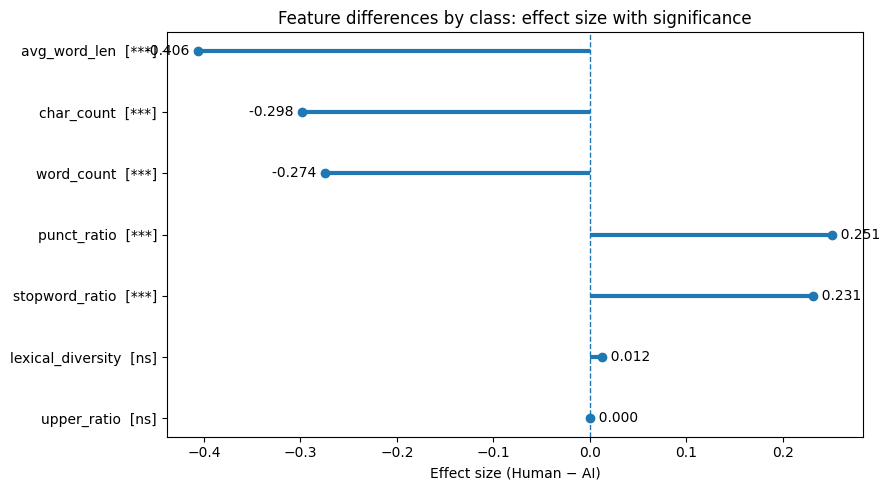

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df = stats_tbl.copy()

# significance stars
bins = [-np.inf, 0.001, 0.01, 0.05, np.inf]
labels = ["***", "**", "*", "ns"]
df["sig"] = pd.cut(df["p_value"], bins=bins, labels=labels)

# sort by absolute effect so the biggest differences are at the bottom
df = df.sort_values("effect", key=lambda s: s.abs())

y = np.arange(len(df))

plt.figure(figsize=(9,5))
# draw a line from 0 to each effect
for i, v in enumerate(df["effect"]):
    plt.hlines(y=i, xmin=0, xmax=v, linewidth=3)
# endpoints
plt.plot(df["effect"], y, "o")

plt.axvline(0, linestyle="--", linewidth=1)
plt.yticks(y, df["feature"] + "  [" + df["sig"].astype(str) + "]")
# If you mixed Cohen's d and Cliff's δ, keep the generic label:
xlabel = "Effect size (Human − AI)"
plt.xlabel(xlabel)
plt.title("Feature differences by class: effect size with significance")
# annotate numeric value next to each point
for i, v in enumerate(df["effect"]):
    ha = "left" if v >= 0 else "right"
    plt.text(v, i, f"  {v:.3f}" if v >= 0 else f"{v:.3f}  ", va="center", ha=ha)
plt.tight_layout()
plt.show()


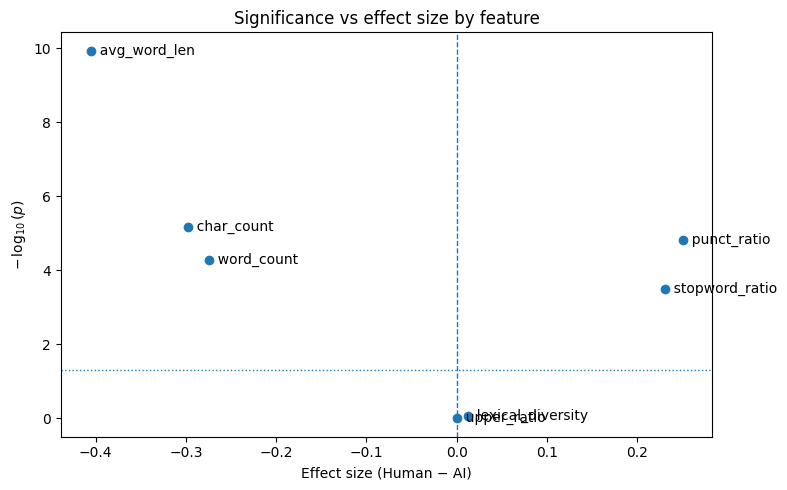

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

dfv = stats_tbl.copy().dropna(subset=["p_value"])
# avoid log(0)
dfv["neglog10p"] = -np.log10(np.clip(dfv["p_value"], 1e-300, 1))

plt.figure(figsize=(8,5))
plt.scatter(dfv["effect"], dfv["neglog10p"])
plt.axvline(0, linestyle="--", linewidth=1)
plt.axhline(-np.log10(0.05), linestyle=":", linewidth=1)  # p=0.05 line
plt.xlabel("Effect size (Human − AI)")
plt.ylabel(r"$-\,\log_{10}(p)$")
plt.title("Significance vs effect size by feature")
# label points
for _, r in dfv.iterrows():
    plt.text(r["effect"], r["neglog10p"], "  " + r["feature"], va="center")
plt.tight_layout()
plt.show()


In [ ]:
display_cols = ["feature","test","p_value","effect","effect_name","n_human","n_ai"]
tbl = (stats_tbl[display_cols]
       .assign(p_value=lambda d: d["p_value"].map(lambda x: f"{x:.2e}"),
               effect=lambda d: d["effect"].map(lambda x: f"{x:+.3f}")))
tbl


,feature,test,p_value,effect,effect_name,n_human,n_ai
2,avg_word_len,Welch t,1.17e-10,-0.406,Cohen_d,605,358
1,char_count,Welch t,6.81e-06,-0.298,Cohen_d,605,358
4,punct_ratio,Welch t,1.54e-05,+0.251,Cohen_d,605,358
0,word_count,Welch t,5.18e-05,-0.274,Cohen_d,605,358
5,stopword_ratio,Welch t,3.28e-04,+0.231,Cohen_d,605,358
6,lexical_diversity,Welch t,8.51e-01,+0.012,Cohen_d,605,358
3,upper_ratio,Mann–Whitney U,1.00e+00,+0.000,Cliffs_delta,605,358


In [ ]:
from scipy.stats import ttest_ind, f_oneway

# Split by class
human_bat = df_bataineh[df_bataineh['label_cat'] == 'human']
ai_bat = df_bataineh[df_bataineh['label_cat'] == 'ai']

features = ['word_count', 'char_count', 'avg_word_len', 'upper_ratio',
            'punct_ratio', 'stopword_ratio', 'lexical_diversity']

for feature in features:
    print(f"\n🔍 Feature: {feature}")

    # T-test
    t_stat, t_pval = ttest_ind(human_bat[feature], ai_bat[feature], equal_var=False, nan_policy='omit')
    print(f"📌 T-test p-value: {t_pval:.5f} {'✅ Significant' if t_pval < 0.05 else '❌ Not Significant'}")

    # ANOVA
    f_stat, f_pval = f_oneway(human_bat[feature], ai_bat[feature])
    print(f"📌 ANOVA p-value: {f_pval:.5f} {'✅ Significant' if f_pval < 0.05 else '❌ Not Significant'}")



🔍 Feature: word_count
📌 T-test p-value: nan ❌ Not Significant
📌 ANOVA p-value: nan ❌ Not Significant

🔍 Feature: char_count
📌 T-test p-value: nan ❌ Not Significant
📌 ANOVA p-value: nan ❌ Not Significant

🔍 Feature: avg_word_len
📌 T-test p-value: nan ❌ Not Significant
📌 ANOVA p-value: nan ❌ Not Significant

🔍 Feature: upper_ratio
📌 T-test p-value: nan ❌ Not Significant
📌 ANOVA p-value: nan ❌ Not Significant

🔍 Feature: punct_ratio
📌 T-test p-value: nan ❌ Not Significant
📌 ANOVA p-value: nan ❌ Not Significant

🔍 Feature: stopword_ratio
📌 T-test p-value: nan ❌ Not Significant
📌 ANOVA p-value: nan ❌ Not Significant

🔍 Feature: lexical_diversity
📌 T-test p-value: nan ❌ Not Significant
📌 ANOVA p-value: nan ❌ Not Significant


/usr/local/lib/python3.12/dist-packages/scipy/_lib/deprecation.py:234: SmallSampleWarning: One or more sample arguments is too small; all returned values will be NaN. See documentation for sample size requirements.
  return f(*args, **kwargs)
/tmp/ipython-input-224828686.py:18: SmallSampleWarning: One or more sample arguments is too small; all returned values will be NaN. See documentation for sample size requirements.
  f_stat, f_pval = f_oneway(human_bat[feature], ai_bat[feature])


 Correlation Matrix (Heatmap)

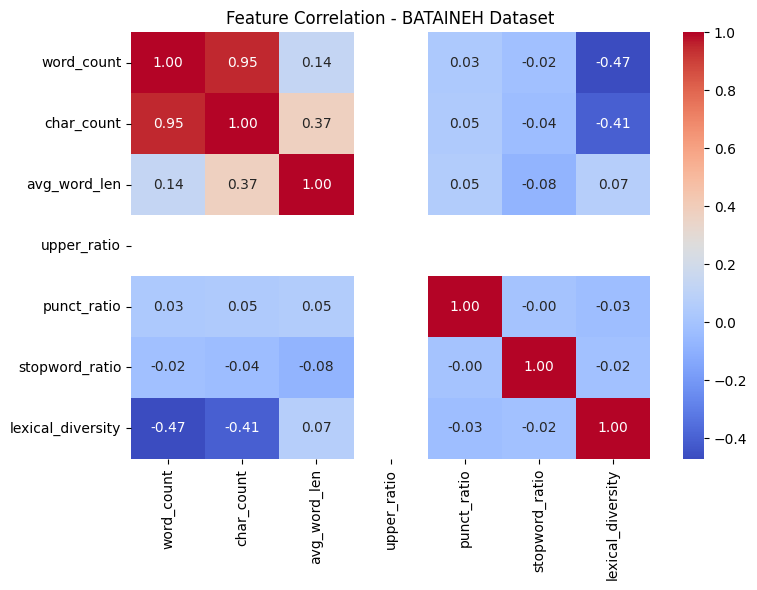

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))
sns.heatmap(df_bataineh[features].corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Feature Correlation - BATAINEH Dataset")
plt.tight_layout()
plt.show()


Distribution Plots for Selected Features

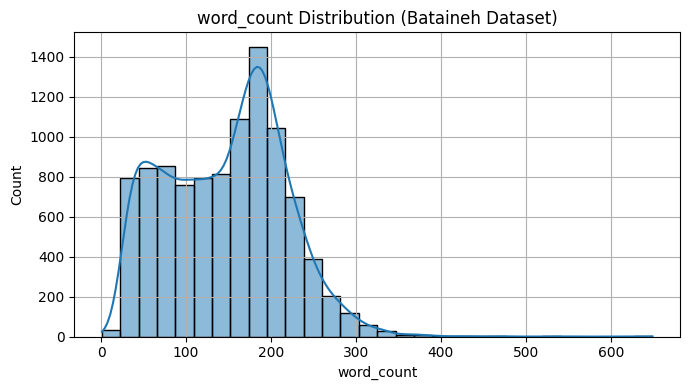

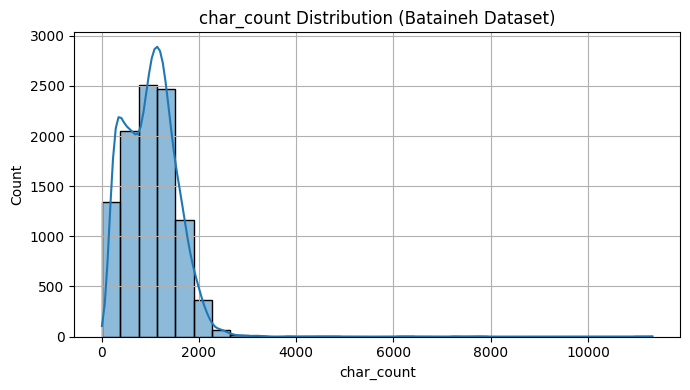

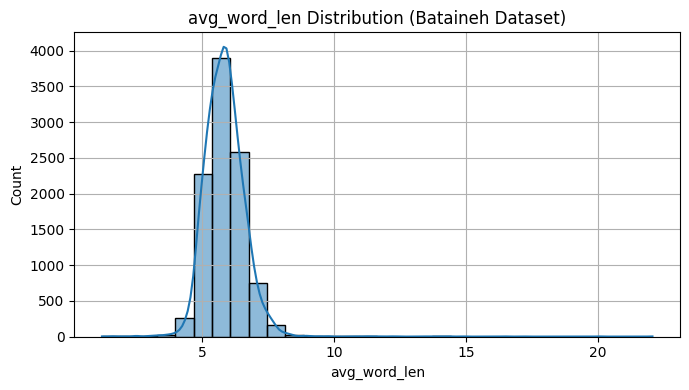

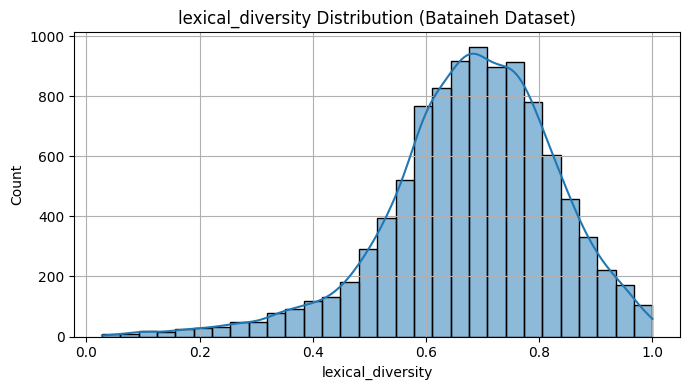

In [ ]:
import seaborn as sns

for feature in ['word_count', 'char_count', 'avg_word_len', 'lexical_diversity']:
    plt.figure(figsize=(7, 4))
    sns.histplot(df_bataineh[feature], bins=30, kde=True)
    plt.title(f'{feature} Distribution (Bataineh Dataset)')
    plt.xlabel(feature)
    plt.ylabel("Count")
    plt.grid(True)
    plt.tight_layout()
    plt.show()


## Step 1: Train a Simple Model (e.g., Random Forest)

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split

# Select features and label
X_bataineh = df_bataineh[['word_count', 'char_count', 'avg_word_len', 'upper_ratio',
                          'punct_ratio', 'stopword_ratio', 'lexical_diversity']]
y_bataineh = df_bataineh['label'].astype(int)  # Make sure it's numeric

# Split dataset
X_train_b, X_test_b, y_train_b, y_test_b = train_test_split(X_bataineh, y_bataineh, test_size=0.2, random_state=42)

# Train RF model
rf_b_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_b_model.fit(X_train_b, y_train_b)


RandomForestClassifier(random_state=42)

✅ Accuracy: 0.7410

📋 Classification Report:
              precision    recall  f1-score   support

           0       0.74      0.76      0.75      1012
           1       0.75      0.72      0.73       988

    accuracy                           0.74      2000
   macro avg       0.74      0.74      0.74      2000
weighted avg       0.74      0.74      0.74      2000



/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


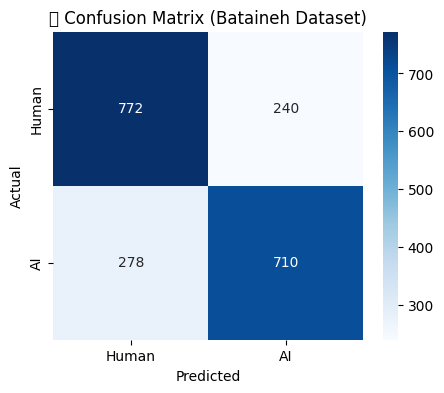

🧠 ROC AUC Score: 0.8281


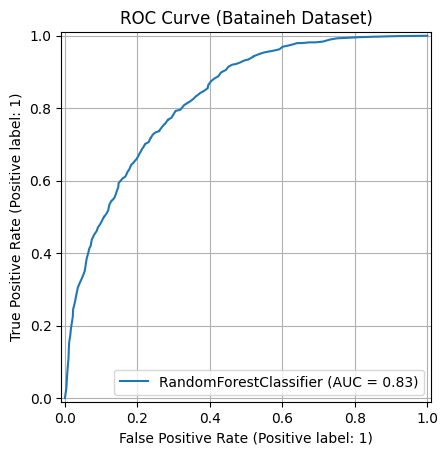

In [ ]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_auc_score, RocCurveDisplay
import matplotlib.pyplot as plt
import seaborn as sns

# Step 1: Predict on test set
y_pred_b = rf_b_model.predict(X_test_b)
y_proba_b = rf_b_model.predict_proba(X_test_b)[:, 1]  # For ROC AUC

# Step 2: Accuracy
acc_b = accuracy_score(y_test_b, y_pred_b)
print(f"✅ Accuracy: {acc_b:.4f}")

# Step 3: Classification report
print("\n📋 Classification Report:")
print(classification_report(y_test_b, y_pred_b))

# Step 4: Confusion matrix
cm_b = confusion_matrix(y_test_b, y_pred_b)
plt.figure(figsize=(5, 4))
sns.heatmap(cm_b, annot=True, fmt='d', cmap='Blues', xticklabels=['Human', 'AI'], yticklabels=['Human', 'AI'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('📊 Confusion Matrix (Bataineh Dataset)')
plt.show()

# Step 5: ROC AUC Score
roc_auc = roc_auc_score(y_test_b, y_proba_b)
print(f"🧠 ROC AUC Score: {roc_auc:.4f}")

# Step 6: ROC Curve
RocCurveDisplay.from_estimator(rf_b_model, X_test_b, y_test_b)
plt.title('ROC Curve (Bataineh Dataset)')
plt.grid()
plt.show()


Run SHAP on Bataineh Model

In [ ]:
from xgboost import XGBClassifier

# Train the model (replace with your correct training data)
xgb_model = XGBClassifier()
xgb_model.fit(X_train_b, y_train_b)


XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric=None, feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=None, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=None,
              n_jobs=None, num_parallel_tree=None, ...)

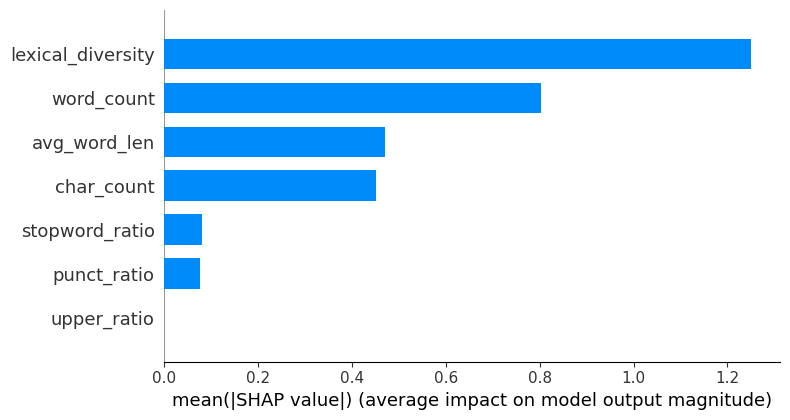

In [ ]:
explainer = shap.TreeExplainer(xgb_model)
shap_values_xgb = explainer.shap_values(X_test_b_df)
shap.summary_plot(shap_values_xgb, X_test_b_df, plot_type="bar")


In [ ]:
import pandas as pd
importance_df_xgb = pd.DataFrame({
    'Feature': X_test_b_df.columns,
    'Mean |SHAP|': np.abs(shap_values_xgb).mean(axis=0)
}).sort_values(by='Mean |SHAP|', ascending=False)

importance_df_xgb


,Feature,Mean |SHAP|
6,lexical_diversity,1.249848
0,word_count,0.802936
2,avg_word_len,0.469978
1,char_count,0.451806
5,stopword_ratio,0.079182
4,punct_ratio,0.076342
3,upper_ratio,0.000000


In [ ]:
importance_df_xgb.to_csv("xgb_shap_importance.csv", index=False)


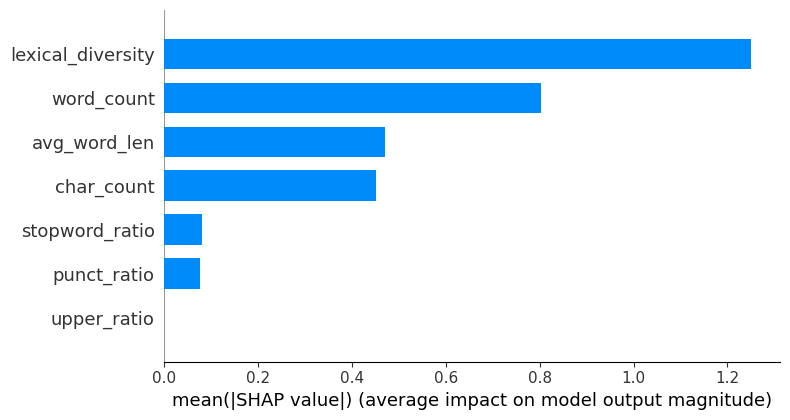

In [ ]:
import matplotlib.pyplot as plt
shap.summary_plot(shap_values_xgb, X_test_b_df, plot_type="bar", show=False)
plt.savefig("xgb_shap_summary_bar.png", dpi=300, bbox_inches='tight')


## MLP

Import Libraries

In [ ]:
import pandas as pd
import numpy as np

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping


Load the Bataineh Dataset

In [ ]:
# Load data
df = pd.read_csv("3-Bataineh dataset.csv")

# Features and labels
texts = df["processed_text"].astype(str)  # Ensure it's string
labels = df["label"]


TF-IDF Vectorization

In [ ]:
# TF-IDF Vectorizer
tfidf = TfidfVectorizer(max_features=5000)
X = tfidf.fit_transform(texts)
y = labels.values


Train-Test Split

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Convert sparse matrices to dense
X_train = X_train.toarray()
X_test = X_test.toarray()


Build and Train the MLP Model

In [ ]:
model = Sequential([
    Dense(256, activation='relu', input_shape=(X_train.shape[1],)),
    Dropout(0.3),
    Dense(128, activation='relu'),
    Dropout(0.3),
    Dense(1, activation='sigmoid')
])

model.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])

# Train model
early_stop = EarlyStopping(monitor='val_loss', patience=3)
model.fit(X_train, y_train, validation_data=(X_test, y_test), epochs=10, batch_size=32, callbacks=[early_stop])


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/10
250/250 ━━━━━━━━━━━━━━━━━━━━ 7s 21ms/step - accuracy: 0.7607 - loss: 0.4660 - val_accuracy: 0.9150 - val_loss: 0.2105
Epoch 2/10
250/250 ━━━━━━━━━━━━━━━━━━━━ 6s 24ms/step - accuracy: 0.9739 - loss: 0.0826 - val_accuracy: 0.9065 - val_loss: 0.2405
Epoch 3/10
250/250 ━━━━━━━━━━━━━━━━━━━━ 5s 19ms/step - accuracy: 0.9929 - loss: 0.0325 - val_accuracy: 0.9020 - val_loss: 0.3398
Epoch 4/10
250/250 ━━━━━━━━━━━━━━━━━━━━ 6s 23ms/step - accuracy: 0.9969 - loss: 0.0111 - val_accuracy: 0.9010 - val_loss: 0.3893


Evaluate the Model

In [ ]:
# Predict
y_pred_prob = model.predict(X_test)
y_pred = (y_pred_prob > 0.5).astype(int)

# Evaluation
print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred))
print("Accuracy:", accuracy_score(y_test, y_pred))


63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
[[914  98]
 [100 888]]
              precision    recall  f1-score   support

           0       0.90      0.90      0.90      1012
           1       0.90      0.90      0.90       988

    accuracy                           0.90      2000
   macro avg       0.90      0.90      0.90      2000
weighted avg       0.90      0.90      0.90      2000

Accuracy: 0.901


 Save the Model and Vectorizer

In [ ]:
# Save model
model.save("mlp_bataineh_model.h5")

# Save TF-IDF vectorizer
import pickle
with open("tfidf_bataineh.pkl", "wb") as f:
    pickle.dump(tfidf, f)


metrics, curves, and SHAP (MLP)

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step
Confusion matrix:
 [[919  93]
 [104 884]]

Classification report:
               precision    recall  f1-score   support

           0       0.90      0.91      0.90      1012
           1       0.90      0.89      0.90       988

    accuracy                           0.90      2000
   macro avg       0.90      0.90      0.90      2000
weighted avg       0.90      0.90      0.90      2000

Accuracy: 0.9015
ROC-AUC: 0.9681549143076603
PR-AUC: 0.9674400769250481


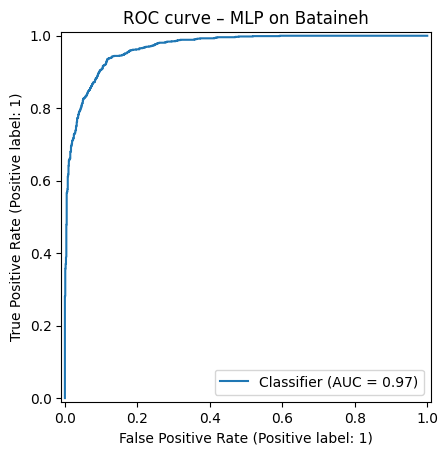

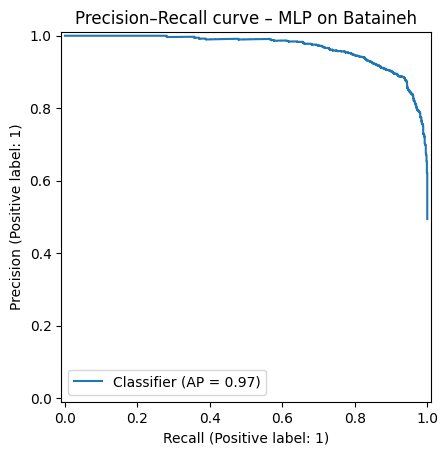

Best F1 threshold ~ 0.15 with F1 = 0.909


In [ ]:
# --- Predictions & basic metrics ---
y_prob = model.predict(X_test).ravel()              # probabilities for class 1 (AI)
y_pred = (y_prob > 0.5).astype(int)

from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
print("Confusion matrix:\n", confusion_matrix(y_test, y_pred))
print("\nClassification report:\n", classification_report(y_test, y_pred, digits=2))
print("Accuracy:", accuracy_score(y_test, y_pred))

# --- ROC-AUC and PR-AUC with plots ---
from sklearn.metrics import roc_auc_score, RocCurveDisplay, PrecisionRecallDisplay, average_precision_score
import matplotlib.pyplot as plt

print("ROC-AUC:", roc_auc_score(y_test, y_prob))
print("PR-AUC:", average_precision_score(y_test, y_prob))

RocCurveDisplay.from_predictions(y_test, y_prob)
plt.title("ROC curve – MLP on Bataineh"); plt.show()

PrecisionRecallDisplay.from_predictions(y_test, y_prob)
plt.title("Precision–Recall curve – MLP on Bataineh"); plt.show()

# --- Optional: choose a threshold that matches your goal (e.g., max F1 or minimize false positives) ---
import numpy as np
from sklearn.metrics import f1_score
ths = np.linspace(0.05, 0.95, 19)
best = max(((t, f1_score(y_test, (y_prob>t).astype(int))) for t in ths), key=lambda x: x[1])
print(f"Best F1 threshold ~ {best[0]:.2f} with F1 = {best[1]:.3f}")


63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step


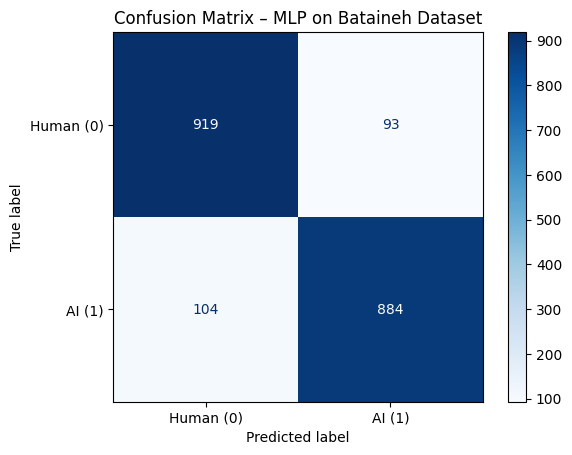

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Predict (you already have this from before)
y_prob = model.predict(X_test).ravel()
y_pred = (y_prob > 0.5).astype(int)

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

# Plot confusion matrix
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Human (0)", "AI (1)"])
disp.plot(cmap="Blues", values_format="d")
plt.title("Confusion Matrix – MLP on Bataineh Dataset")
plt.show()


63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step


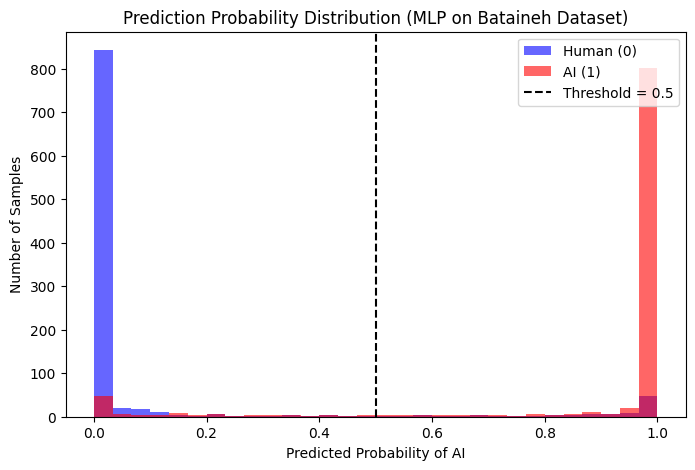

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Get prediction probabilities
y_prob = model.predict(X_test).ravel()

# Separate Human (0) and AI (1) probabilities
human_probs = y_prob[y_test == 0]
ai_probs = y_prob[y_test == 1]

# Plot histograms
plt.figure(figsize=(8,5))
plt.hist(human_probs, bins=30, alpha=0.6, label="Human (0)", color="blue")
plt.hist(ai_probs, bins=30, alpha=0.6, label="AI (1)", color="red")
plt.axvline(0.5, color="black", linestyle="--", label="Threshold = 0.5")

plt.xlabel("Predicted Probability of AI")
plt.ylabel("Number of Samples")
plt.title("Prediction Probability Distribution (MLP on Bataineh Dataset)")
plt.legend()
plt.show()


SHAP for the MLP (tabular TF‑IDF features)

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step


  0%|          | 0/50 [00:00<?, ?it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step
3125/3125 ━━━━━━━━━━━━━━━━━━━━ 16s 5ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 71ms/step
3125/3125 ━━━━━━━━━━━━━━━━━━━━ 16s 5ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step
3125/3125 ━━━━━━━━━━━━━━━━━━━━ 16s 5ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 71ms/step
3125/3125 ━━━━━━━━━━━━━━━━━━━━ 16s 5ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step
3125/3125 ━━━━━━━━━━━━━━━━━━━━ 15s 5ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step
3125/3125 ━━━━━━━━━━━━━━━━━━━━ 16s 5ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step
3125/3125 ━━━━━━━━━━━━━━━━━━━━ 15s 5ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 74ms/step
3125/3125 ━━━━━━━━━━━━━━━━━━━━ 15s 5ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step
3125/3125 ━━━━━━━━━━━━━━━━━━━━ 16s 5ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step
3125/3125 ━━━━━━━━━━━━━━━━━━━━ 16s 5ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step
3125/3125 ━━━━━━━━━━━━━━━━━━━━ 15s 5ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 73ms/step
3125/3125 ━━━━━━━━━━━━━━━━━━━━ 15s 5ms/step
1/1 ━━━━━━━━━━━━

/tmp/ipython-input-2582891599.py:36: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_vals, X_explain, feature_names=feat_names, plot_type="bar", max_display=20)


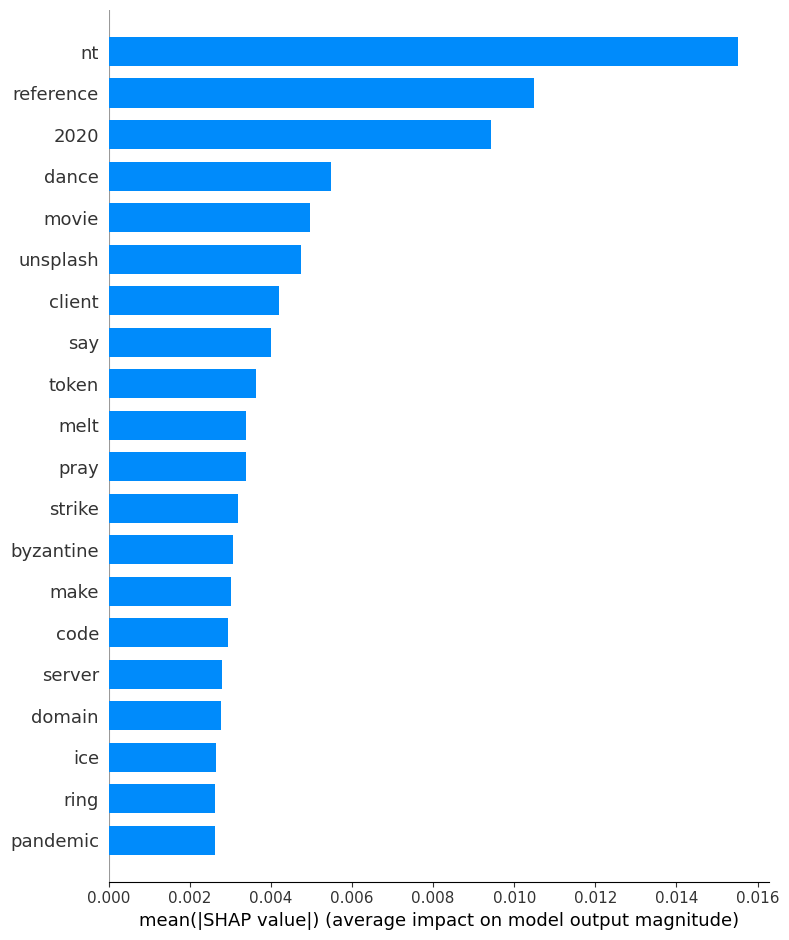

/tmp/ipython-input-2582891599.py:37: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_vals, X_explain, feature_names=feat_names, max_display=20)  # beeswarm


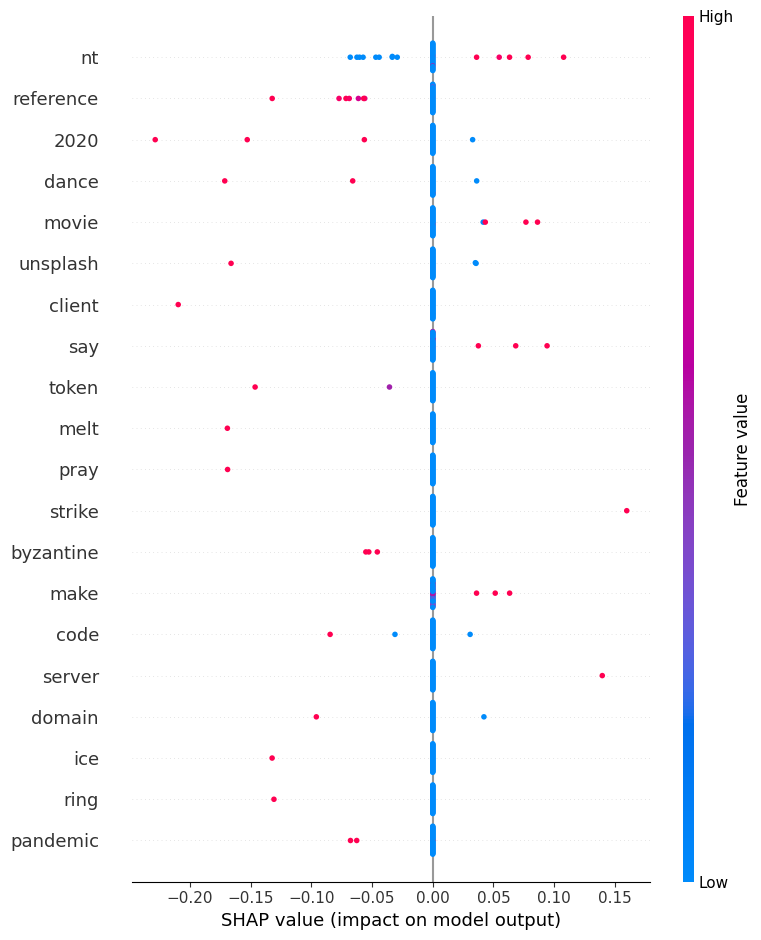

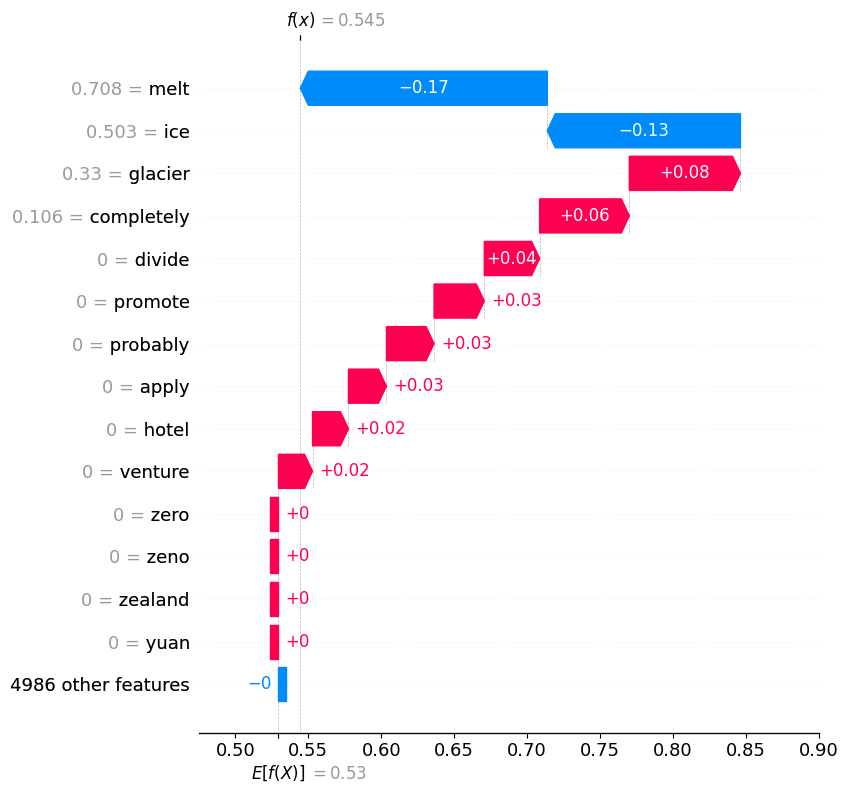

In [ ]:
import numpy as np
import shap
import matplotlib.pyplot as plt

# --- helper: ensure dense arrays for KernelExplainer ---
def to_dense(X):
    return X.toarray() if hasattr(X, "toarray") else np.asarray(X)

# 1) small background sample (speed)
bg_n = min(100, X_train.shape[0])
bg_idx = np.random.choice(X_train.shape[0], size=bg_n, replace=False)
background = to_dense(X_train[bg_idx])

# 2) subset of test rows to explain
k = 50
X_explain = to_dense(X_test[:k])

# 3) predict function that outputs prob for class 1
predict_fn = lambda X: model.predict(X).ravel()

# 4) Build KernelExplainer (classic API, compatible with older SHAP)
explainer = shap.KernelExplainer(predict_fn, background)

# 5) Compute SHAP values (limit samples to control cost)
#    If your SHAP is very new, use 'max_evals=' in shap.Explainer; for KernelExplainer use 'nsamples='
shap_vals = explainer.shap_values(X_explain, nsamples=1000)  # try 500–2000
# shap_vals is (k x n_features) for binary classification

# 6) Feature names (optional, improves plots)
try:
    feat_names = vectorizer.get_feature_names_out()
except:
    feat_names = None

# 7) Global importance plots
shap.summary_plot(shap_vals, X_explain, feature_names=feat_names, plot_type="bar", max_display=20)
shap.summary_plot(shap_vals, X_explain, feature_names=feat_names, max_display=20)  # beeswarm

# 8) Local explanation (pick one example)
i = 0
exp_i = shap.Explanation(values=shap_vals[i],
                         base_values=explainer.expected_value,
                         data=X_explain[i],
                         feature_names=feat_names)
shap.plots.waterfall(exp_i, max_display=15)


## Sample Streamlit code for a minimal version:

In [ ]:
%pip install -q streamlit tensorflow scikit-learn pyngrok


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.3/44.3 kB 2.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.9/9.9 MB 69.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.9/6.9 MB 93.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.1/79.1 kB 5.3 MB/s eta 0:00:00


In [ ]:
%%writefile app.py
# (paste the Streamlit code you have here)


Writing app.py


In [ ]:
# 0) Clean up any old processes (ignore errors)
!pkill -f streamlit || true
!pkill -f cloudflared || true


^C
^C


In [ ]:
# 1) Start Streamlit on port 8501
!streamlit run app.py --server.port 8501 --server.headless true &>/content/streamlit.log &


In [ ]:
# 2) Download cloudflared if missing
![[ -f cloudflared ]] || (wget -q https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64 -O cloudflared && chmod +x cloudflared)


In [ ]:
# 3) Open a tunnel and log output
!./cloudflared tunnel --url http://localhost:8501 --no-autoupdate > /content/cf.log 2>&1 &


In [ ]:
# 4) Wait for the public URL (poll the log for up to ~30s)
import re, time, os

pattern = re.compile(r"(https://[-0-9a-z]+\.trycloudflare\.com)")
url = None
for _ in range(30):
    if os.path.exists("/content/cf.log"):
        with open("/content/cf.log") as f:
            m = pattern.search(f.read())
            if m:
                url = m.group(1)
                break
    time.sleep(1)

if url:
    print("App URL:", url)
else:
    print("URL not found yet. Last 80 log lines:\n")
    print("\n".join(open("/content/cf.log").read().splitlines()[-80:]))


App URL: https://german-period-cr-temporal.trycloudflare.com


In [ ]:
!pkill -f streamlit || true
!pkill -f cloudflared || true


^C
^C


In [ ]:
%%writefile app.py
import streamlit as st
import tensorflow as tf
import pickle
import numpy as np

st.set_page_config(page_title="AI vs Human Text Detector", layout="centered")
st.title("AI vs Human Text Detector (MLP + TF-IDF)")

@st.cache_resource(show_spinner="Loading model & vectorizer…")
def load_resources():
    model = tf.keras.models.load_model("mlp_bataineh_model.h5")
    with open("tfidf_bataineh.pkl", "rb") as f:
        vectorizer = pickle.load(f)
    return model, vectorizer

try:
    model, vectorizer = load_resources()
except Exception as e:
    st.error(f"Failed to load model/vectorizer: {e}")
    st.stop()

st.write("Enter text below or upload a .txt file.")

uploaded = st.file_uploader("Upload .txt", type=["txt"])
text_input = ""
if uploaded is not None:
    try:
        text_input = uploaded.read().decode("utf-8", errors="ignore")
    except Exception as e:
        st.error(f"File read error: {e}")

if not text_input:
    text_input = st.text_area("Or paste text here:", height=200)

threshold = st.slider("Decision threshold", 0.0, 1.0, 0.50, 0.01)

def predict(text: str):
    X = vectorizer.transform([text]).toarray()  # match your training
    prob = float(model.predict(X, verbose=0)[0][0])  # sigmoid output
    label = "AI-generated" if prob >= threshold else "Human-written"
    return label, prob

if st.button("Analyze"):
    if text_input.strip():
        with st.spinner("Analyzing…"):
            label, prob = predict(text_input)
        st.success(f"Prediction: {label}")
        st.metric("Confidence", f"{prob:.3f}")
        st.caption(f"Threshold: {threshold:.2f}")
    else:
        st.warning("Please provide some text or upload a file first.")


Overwriting app.py


In [ ]:
!streamlit run app.py --server.port 8501 --server.address 0.0.0.0 \
  --server.headless true --server.enableCORS false --server.enableXsrfProtection false \
  &>/content/streamlit.log &

# Health check (should print: "ok")
!curl -s localhost:8501/_stcore/health || true


In [ ]:
!tail -n 120 /content/streamlit.log


In [ ]:
# Download cloudflared if needed
![[ -f cloudflared ]] || (wget -q https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64 -O cloudflared && chmod +x cloudflared)

# Open the tunnel
!./cloudflared tunnel --url http://localhost:8501 --no-autoupdate > /content/cf.log 2>&1 &

# Wait for URL
import re, time, os
pattern = re.compile(r"(https://[-0-9a-z]+\.trycloudflare\.com)")
url = None
for _ in range(30):
    if os.path.exists("/content/cf.log"):
        m = pattern.search(open("/content/cf.log").read())
        if m: url = m.group(1); break
    time.sleep(1)
print("App URL:", url if url else "Not found")


App URL: https://republic-felt-called-chuck.trycloudflare.com


In [ ]:
# app.py — simple UI + short-text + uncertainty band
import streamlit as st
import tensorflow as tf
import pickle

st.set_page_config(page_title="AI vs Human Text Detector", layout="centered")
st.title("AI vs Human Text Detector (MLP + TF-IDF)")

# ---------- Load resources ----------
@st.cache_resource(show_spinner="Loading model & vectorizer…")
def load_resources():
    model = tf.keras.models.load_model("mlp_bataineh_model.h5")
    with open("tfidf_bataineh.pkl", "rb") as f:
        vectorizer = pickle.load(f)
    # Optional: load a calibrator if you trained one (ignore if missing)
    try:
        with open("calibrator_isotonic.pkl", "rb") as f:
            calibrator = pickle.load(f)
    except Exception:
        calibrator = None
    return model, vectorizer, calibrator

try:
    model, vectorizer, calibrator = load_resources()
except Exception as e:
    st.error(f"Failed to load model/vectorizer: {e}")
    st.stop()

# ---------- Input ----------
st.write("Enter text below or upload a .txt file.")
uploaded = st.file_uploader("Upload .txt", type=["txt"])
text_input = ""
if uploaded is not None:
    try:
        text_input = uploaded.read().decode("utf-8", errors="ignore")
    except Exception as e:
        st.error(f"File read error: {e}")

if not text_input:
    text_input = st.text_area("Or paste text here:", height=220)

# ---------- Short-text guard ----------
analyzer = vectorizer.build_analyzer()
token_count = len(analyzer(text_input)) if text_input else 0
if 0 < token_count < 30:
    st.warning(
        f"Short input detected ({token_count} tokens). "
        "Predictions on very short texts can be unreliable. "
        "Consider raising the threshold (e.g., 0.75–0.90) or adding more text."
    )

# ---------- Controls ----------
threshold = st.slider("Decision threshold", 0.0, 1.0, 0.50, 0.01)
# Uncertainty band (±margin around threshold)
margin = 0.08

# ---------- Predict helper ----------
def predict_prob(text: str) -> float:
    X = vectorizer.transform([text]).toarray()  # match your training
    prob = float(model.predict(X, verbose=0)[0][0])  # sigmoid output (AI class prob)
    if calibrator is not None:
        # optional probability calibration if you provided calibrator file
        prob = float(calibrator.transform([prob])[0])
    return prob

# ---------- Action ----------
if st.button("Analyze"):
    if text_input.strip():
        with st.spinner("Analyzing…"):
            prob = predict_prob(text_input)

        # Apply uncertainty band around threshold
        if prob >= threshold + margin:
            label = "AI-generated"
        elif prob <= threshold - margin:
            label = "Human-written"
        else:
            label = "Undetermined (near boundary)"

        # ---------- Output ----------
        st.subheader("Result")
        st.write(f"**Prediction:** {label}")
        st.metric("Confidence", f"{prob:.3f}")
        st.caption(f"Threshold: {threshold:.2f} • Uncertainty margin: ±{margin:.02f}")

        if label.startswith("Undetermined"):
            st.info(
                "This result falls within the uncertainty band. "
                "Consider raising the threshold or providing more text."
            )
    else:
        st.warning("Please provide some text or upload a file first.")


2025-08-20 08:33:01.454 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2025-08-20 08:33:01.461 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2025-08-20 08:33:03.805 
  command:

    streamlit run /usr/local/lib/python3.12/dist-packages/colab_kernel_launcher.py [ARGUMENTS]
2025-08-20 08:33:03.808 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2025-08-20 08:33:03.817 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2025-08-20 08:33:03.840 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2025-08-20 08:33:03.844 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when runn

In [ ]:
import pandas as pd, pickle
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score, precision_recall_curve
import numpy as np

# 1) load your data (edit column names!)
df = pd.read_csv("3-Bataineh dataset.csv")
texts = df["text"].astype(str).tolist()   # <-- change to your text column
labels = df["label"].astype(int).values   # <-- change to your label column (0=human,1=AI)

# 2) split a validation set
X_train_txt, X_val_txt, y_train, y_val = train_test_split(
    texts, labels, test_size=0.2, stratify=labels, random_state=42
)

# 3) vectorize with your saved TF-IDF (don’t refit!)
with open("tfidf_bataineh.pkl","rb") as f:
    tfidf = pickle.load(f)
X_val_dl = tfidf.transform(X_val_txt).toarray()

# 4) probs on validation
probs_val = model.predict(X_val_dl, verbose=0).ravel()

# 5) choose a threshold
grid = np.linspace(0, 1, 201)
f1s = [f1_score(y_val, probs_val >= t) for t in grid]
best_t = float(grid[int(np.argmax(f1s))])
print("Best F1 threshold:", best_t)


Best F1 threshold: 0.23


In [ ]:
import json
with open("threshold.json","w") as f:
    json.dump({"threshold": best_t}, f)


In [ ]:
import os, json

def load_threshold(default=0.5):
    if os.path.exists("threshold.json"):
        try:
            return float(json.load(open("threshold.json"))["threshold"])
        except:
            pass
    return default

threshold_default = load_threshold(0.5)
threshold = st.slider("Decision threshold", 0.0, 1.0, threshold_default, 0.01)


2025-08-20 08:34:41.864 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2025-08-20 08:34:41.866 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2025-08-20 08:34:41.867 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2025-08-20 08:34:41.869 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2025-08-20 08:34:41.870 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2025-08-20 08:34:41.871 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.


In [ ]:
# app.py — simple UI + short-text guard + uncertainty band + JSON default threshold
import os, json, pickle
import streamlit as st
import tensorflow as tf

st.set_page_config(page_title="AI vs Human Text Detector", layout="centered")
st.title("AI vs Human Text Detector (MLP + TF-IDF)")

# ----- load model/vectorizer (and optional calibrator) -----
@st.cache_resource(show_spinner="Loading model & vectorizer…")
def load_resources():
    model = tf.keras.models.load_model("mlp_bataineh_model.h5")
    with open("tfidf_bataineh.pkl", "rb") as f:
        vectorizer = pickle.load(f)
    try:
        with open("calibrator_isotonic.pkl", "rb") as f:
            calibrator = pickle.load(f)
    except Exception:
        calibrator = None
    return model, vectorizer, calibrator

# default threshold from JSON (falls back to 0.5)
def load_threshold(default=0.5):
    try:
        return float(json.load(open("threshold.json"))["threshold"])
    except Exception:
        return default

model, vectorizer, calibrator = load_resources()
threshold_default = load_threshold(0.5)   # <- will be 0.14 from your file

# ----- inputs -----
st.write("Enter text below or upload a .txt file.")
uploaded = st.file_uploader("Upload .txt", type=["txt"])
text_input = ""
if uploaded is not None:
    try:
        text_input = uploaded.read().decode("utf-8", errors="ignore")
    except Exception as e:
        st.error(f"File read error: {e}")

if not text_input:
    text_input = st.text_area("Or paste text here:", height=220)

# ----- short-text guard -----
analyzer = vectorizer.build_analyzer()
token_count = len(analyzer(text_input)) if text_input else 0
if 0 < token_count < 30:
    st.warning(
        f"Short input detected ({token_count} tokens). Predictions may be unreliable. "
        "Consider raising the threshold (e.g., 0.75–0.90) or adding more text."
    )

# ----- controls -----
threshold = st.slider("Decision threshold", 0.0, 1.0, threshold_default, 0.01)
margin = 0.08  # uncertainty band ±8%

# ----- predict helper -----
def predict_prob(text: str) -> float:
    X = vectorizer.transform([text]).toarray()
    prob = float(model.predict(X, verbose=0)[0][0])  # sigmoid for AI class
    if calibrator is not None:
        prob = float(calibrator.transform([prob])[0])
    return prob

# ----- action -----
if st.button("Analyze"):
    if text_input.strip():
        with st.spinner("Analyzing…"):
            prob = predict_prob(text_input)

        # apply uncertainty band around threshold
        if prob >= threshold + margin:
            label = "AI-generated"
        elif prob <= threshold - margin:
            label = "Human-written"
        else:
            label = "Undetermined (near boundary)"

        st.subheader("Result")
        st.write(f"**Prediction:** {label}")
        st.metric("Confidence", f"{prob:.3f}")
        st.caption(
            f"Threshold: {threshold:.2f} (default {threshold_default:.2f}) • "
            f"Uncertainty margin: ±{margin:.02f}"
        )

        if label.startswith("Undetermined"):
            st.info("Near the decision boundary — consider raising the threshold or adding more text.")
    else:
        st.warning("Please provide some text or upload a file first.")


2025-08-20 08:34:43.590 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2025-08-20 08:34:43.592 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2025-08-20 08:34:43.593 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2025-08-20 08:34:43.594 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2025-08-20 08:34:43.598 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2025-08-20 08:34:43.599 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2025-08-20 08:34:43.600 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2025-08-20 08:34:43.602 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bar

In [ ]:
!pkill -f streamlit || true
PORT=8502
!streamlit run app.py --server.port $PORT --server.address 0.0.0.0 \
  --server.headless true --server.enableCORS false --server.enableXsrfProtection false \
  &>/content/streamlit.log &
!curl -s localhost:$PORT/_stcore/health || echo "not ok"


^C
not ok


In [ ]:
!pkill -f cloudflared || true
![[ -f cloudflared ]] || (wget -q https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64 -O cloudflared && chmod +x cloudflared)
!./cloudflared tunnel --url http://localhost:8502 --no-autoupdate > /content/cf.log 2>&1 &

import re, time, os
url=None
for _ in range(30):
    if os.path.exists("/content/cf.log"):
        m=re.search(r"https://[-0-9a-z]+\.trycloudflare\.com", open("/content/cf.log").read())
        if m: url=m.group(0); break
    time.sleep(1)
print("App URL:", url if url else "Not found")


^C
App URL: https://attempts-transaction-injection-alloy.trycloudflare.com


In [ ]:
import json, os
print(os.listdir())
print("threshold.json:", open("threshold.json").read() if os.path.exists("threshold.json") else "MISSING")


['.config', '3-Bataineh dataset.csv', 'cf.log', 'streamlit.log', 'tfidf_bataineh.pkl', 'app.py', 'cloudflared', 'mlp_bataineh_model.h5', 'threshold.json', 'sample_data']
threshold.json: {"threshold": 0.23}


In [ ]:
!pkill -f streamlit || true
PORT=8502
!streamlit run app.py --server.port $PORT --server.address 0.0.0.0 \
  --server.headless true --server.enableCORS false --server.enableXsrfProtection false \
  &>/content/streamlit.log &


^C


In [ ]:
!pkill -f streamlit || true
PORT=8502
!streamlit run app.py --server.port $PORT --server.address 0.0.0.0 \
  --server.headless true --server.enableCORS false --server.enableXsrfProtection false \
  &>/content/streamlit.log &
!curl -s localhost:$PORT/_stcore/health || echo "not ok"


^C
not ok


In [ ]:
!pkill -f cloudflared || true
![[ -f cloudflared ]] || (wget -q https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64 -O cloudflared && chmod +x cloudflared)
!./cloudflared tunnel --url http://localhost:8502 --no-autoupdate > /content/cf.log 2>&1 &

import re, time, os
url=None
for _ in range(30):
    if os.path.exists("/content/cf.log"):
        m=re.search(r"https://[-0-9a-z]+\.trycloudflare\.com", open("/content/cf.log").read())
        if m: url=m.group(0); break
    time.sleep(1)
print("App URL:", url if url else "Not found")


^C
App URL: https://hawaii-lie-pools-milan.trycloudflare.com


In [ ]:
threshold = st.slider(
    "Decision threshold",
    0.0, 1.0,
    value=threshold_default, step=0.01,
    key=f"threshold_{threshold_default}"  # new key -> picks up new default
)


2025-08-20 08:34:59.713 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2025-08-20 08:34:59.720 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2025-08-20 08:34:59.726 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2025-08-20 08:34:59.728 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2025-08-20 08:34:59.731 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2025-08-20 08:34:59.733 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.


In [ ]:
# ---- restart Streamlit on a clean port and wait for health ----
PORT = 8502

# Kill anything stale
!pkill -f streamlit || true
!pkill -f cloudflared || true
!fuser -k {PORT}/tcp || true

# Start Streamlit
!streamlit run app.py --server.port {PORT} --server.address 0.0.0.0 \
  --server.headless true --server.enableCORS false --server.enableXsrfProtection false \
  &>/content/streamlit.log &

# Wait up to 30s for health = "ok"
import time, subprocess, textwrap, os, re
ok = False
for i in range(30):
    try:
        status = subprocess.check_output(
            ["bash","-lc", f"curl -s localhost:{PORT}/_stcore/health || true"]
        ).decode().strip()
    except Exception:
        status = ""
    if status == "ok":
        print(f"Health: ok (after {i+1}s)")
        ok = True
        break
    time.sleep(1)

if not ok:
    print("Health: not ok — recent Streamlit log:")
    print(subprocess.check_output(
        ["bash","-lc","tail -n 120 /content/streamlit.log || true"]
    ).decode())

# ---- if healthy, open a new Cloudflare tunnel and print the URL ----
if ok:
    ![[ -f cloudflared ]] || (wget -q https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64 -O cloudflared && chmod +x cloudflared)
    !./cloudflared tunnel --url http://localhost:{PORT} --no-autoupdate > /content/cf.log 2>&1 &

    url = None
    for _ in range(30):
        if os.path.exists("/content/cf.log"):
            m = re.search(r"https://[-0-9a-z]+\.trycloudflare\.com", open("/content/cf.log").read())
            if m:
                url = m.group(0)
                break
        time.sleep(1)
    print("App URL:", url if url else "not found — see /content/cf.log")


^C
^C
Health: ok (after 2s)
App URL: https://also-container-ruling-adelaide.trycloudflare.com


## Plot the Confusion Matrix

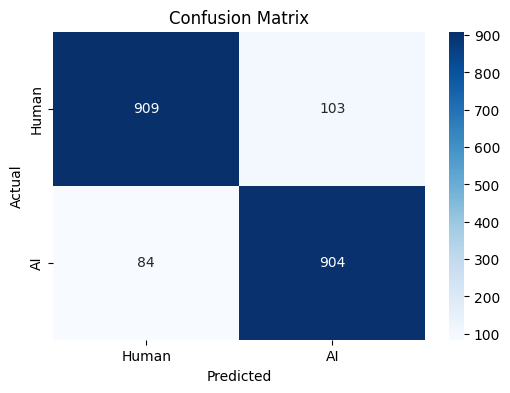

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Human', 'AI'], yticklabels=['Human', 'AI'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()


 Plot the ROC Curve and AUC Score

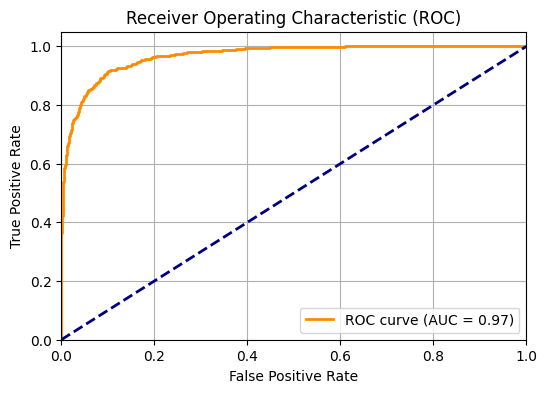

In [ ]:
from sklearn.metrics import roc_curve, auc

# Compute ROC curve and AUC
fpr, tpr, thresholds = roc_curve(y_test, y_pred_prob)
roc_auc = auc(fpr, tpr)

# Plot ROC
plt.figure(figsize=(6, 4))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC)')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()


# Fine Tune model

In [ ]:
import numpy as np
from sklearn.model_selection import KFold
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping


In [ ]:
def create_mlp_model(input_dim, dropout_rate=0.3, hidden_units=128):
    model = Sequential([
        Dense(hidden_units, activation='relu', input_shape=(input_dim,)),
        Dropout(dropout_rate),
        Dense(hidden_units//2, activation='relu'),
        Dropout(dropout_rate),
        Dense(1, activation='sigmoid')
    ])
    model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
    return model


In [ ]:
X = df_bataineh[['word_count', 'char_count', 'avg_word_len', 'upper_ratio',
                 'punct_ratio', 'stopword_ratio', 'lexical_diversity']].values
y = df_bataineh['label'].values

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)


In [ ]:
kf = KFold(n_splits=5, shuffle=True, random_state=42)
fold = 1
accuracies = []

for train_index, val_index in kf.split(X_scaled):
    print(f"Fold {fold} -----------------------")

    X_train, X_val = X_scaled[train_index], X_scaled[val_index]
    y_train, y_val = y[train_index], y[val_index]

    model = create_mlp_model(input_dim=X.shape[1])

    early_stop = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)

    model.fit(X_train, y_train, epochs=10, batch_size=32,
              validation_data=(X_val, y_val), callbacks=[early_stop], verbose=0)

    y_pred = (model.predict(X_val) > 0.5).astype(int)

    acc = accuracy_score(y_val, y_pred)
    accuracies.append(acc)

    print(f"Accuracy for fold {fold}: {acc:.4f}")
    print(classification_report(y_val, y_pred))
    fold += 1

print("\nAverage Accuracy:", np.mean(accuracies))


Fold 1 -----------------------


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
Accuracy for fold 1: 1.0000
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      2000

    accuracy                           1.00      2000
   macro avg       1.00      1.00      1.00      2000
weighted avg       1.00      1.00      1.00      2000

Fold 2 -----------------------


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
Accuracy for fold 2: 1.0000
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      2000

    accuracy                           1.00      2000
   macro avg       1.00      1.00      1.00      2000
weighted avg       1.00      1.00      1.00      2000

Fold 3 -----------------------


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
Accuracy for fold 3: 1.0000
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      2000

    accuracy                           1.00      2000
   macro avg       1.00      1.00      1.00      2000
weighted avg       1.00      1.00      1.00      2000

Fold 4 -----------------------


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
Accuracy for fold 4: 1.0000
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      2000

    accuracy                           1.00      2000
   macro avg       1.00      1.00      1.00      2000
weighted avg       1.00      1.00      1.00      2000

Fold 5 -----------------------


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
Accuracy for fold 5: 1.0000
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      2000

    accuracy                           1.00      2000
   macro avg       1.00      1.00      1.00      2000
weighted avg       1.00      1.00      1.00      2000


Average Accuracy: 1.0


Tuned MLP Model for Bataineh Dataset

In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, BatchNormalization
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping

# ✅ Skip to this if your features are NumPy arrays already
X_train_dl = X_train
X_test_dl = X_test
y_train_dl = y_train
y_test_dl = y_test

# ✅ Define model
model = Sequential([
    Dense(512, activation='relu', input_shape=(X_train_dl.shape[1],)),
    BatchNormalization(),
    Dropout(0.4),
    Dense(256, activation='relu'),
    BatchNormalization(),
    Dropout(0.3),
    Dense(1, activation='sigmoid')  # Binary classification
])

# ✅ Compile
model.compile(
    optimizer=Adam(learning_rate=0.0005),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

# ✅ Early stopping
early_stop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

# ✅ Train
history = model.fit(
    X_train_dl, y_train_dl,
    epochs=30,
    batch_size=64,
    validation_split=0.2,
    callbacks=[early_stop],
    verbose=1
)


Epoch 1/30


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


100/100 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.7041 - loss: 0.6515 - val_accuracy: 0.2887 - val_loss: 0.7707
Epoch 2/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.7500 - loss: 0.5309 - val_accuracy: 0.3787 - val_loss: 0.7737
Epoch 3/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.7493 - loss: 0.5357 - val_accuracy: 0.5075 - val_loss: 0.7249
Epoch 4/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.7701 - loss: 0.4853 - val_accuracy: 0.4875 - val_loss: 0.7279
Epoch 5/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.7620 - loss: 0.4935 - val_accuracy: 0.5600 - val_loss: 0.7209
Epoch 6/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.7676 - loss: 0.4785 - val_accuracy: 0.5412 - val_loss: 0.7448
Epoch 7/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.7761 - loss: 0.4718 - val_accuracy: 0.5725 - val_loss: 0.7595
Epoch 8/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.7761 - loss: 0.4614 - val_accuracy: 0.5725 - va

Evaluate the Model

In [ ]:
# 1. Import Libraries
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping


In [ ]:
# 2. Load Data
df = pd.read_csv("3-Bataineh dataset.csv")

texts = df["processed_text"].astype(str)  # Ensure text is string
labels = df["label"]


In [ ]:
# 3. TF-IDF Vectorization (5000 features)
tfidf = TfidfVectorizer(max_features=5000)
X = tfidf.fit_transform(texts).toarray()  # Convert to dense array
y = labels.values


In [ ]:
# 4. Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


In [ ]:
# 5. Define the MLP Model
model = Sequential([
    Dense(256, activation='relu', input_shape=(5000,)),
    Dropout(0.3),
    Dense(128, activation='relu'),
    Dropout(0.3),
    Dense(1, activation='sigmoid')
])

model.compile(loss='binary_crossentropy',
              optimizer=Adam(learning_rate=0.001),
              metrics=['accuracy'])


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [ ]:
# 6. Early Stopping
early_stop = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)


In [ ]:
# 7. Train the Model
history = model.fit(X_train, y_train,
                    epochs=20,
                    batch_size=32,
                    validation_split=0.2,
                    callbacks=[early_stop],
                    verbose=1)


Epoch 1/20
200/200 ━━━━━━━━━━━━━━━━━━━━ 6s 20ms/step - accuracy: 0.7527 - loss: 0.4930 - val_accuracy: 0.9144 - val_loss: 0.1970
Epoch 2/20
200/200 ━━━━━━━━━━━━━━━━━━━━ 6s 23ms/step - accuracy: 0.9669 - loss: 0.1036 - val_accuracy: 0.9137 - val_loss: 0.2210
Epoch 3/20
200/200 ━━━━━━━━━━━━━━━━━━━━ 4s 19ms/step - accuracy: 0.9931 - loss: 0.0287 - val_accuracy: 0.9087 - val_loss: 0.2811
Epoch 4/20
200/200 ━━━━━━━━━━━━━━━━━━━━ 4s 19ms/step - accuracy: 0.9993 - loss: 0.0072 - val_accuracy: 0.9125 - val_loss: 0.3221


In [ ]:
# 8. Evaluate the Model
y_pred_prob = model.predict(X_test)
y_pred = (y_pred_prob > 0.5).astype(int)

print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))
print("Accuracy:", accuracy_score(y_test, y_pred))


63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step
Confusion Matrix:
 [[947  65]
 [121 867]]

Classification Report:
               precision    recall  f1-score   support

           0       0.89      0.94      0.91      1012
           1       0.93      0.88      0.90       988

    accuracy                           0.91      2000
   macro avg       0.91      0.91      0.91      2000
weighted avg       0.91      0.91      0.91      2000

Accuracy: 0.907


1. Plot Training Curves (Accuracy & Loss)

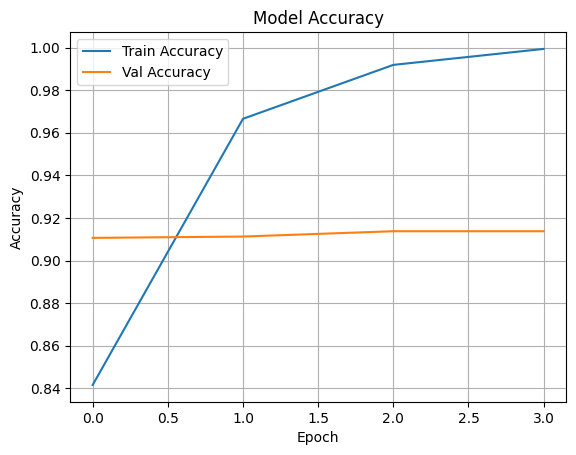

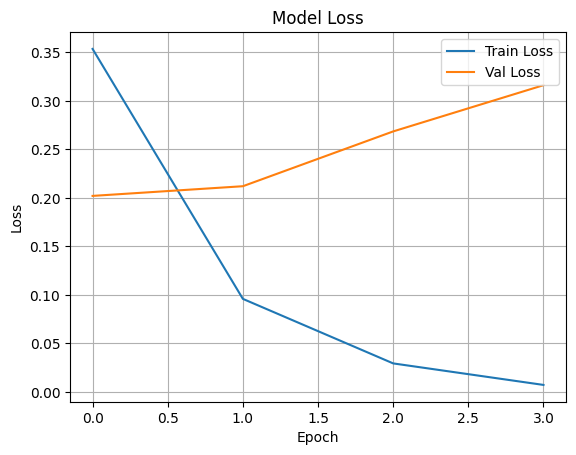

In [ ]:
import matplotlib.pyplot as plt

# Plot training & validation accuracy
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Val Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.show()

# Plot training & validation loss
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()


Save the Trained Model

In [ ]:
# Save model
model.save('mlp_bataineh_model.h5')

# Save TF-IDF vectorizer
import pickle
with open('tfidf_vectorizer.pkl', 'wb') as f:
    pickle.dump(tfidf, f)


Load Later and Predict

In [ ]:
from tensorflow.keras.models import load_model

# Load model
model = load_model('mlp_bataineh_model.h5')

# Load TF-IDF vectorizer
with open('tfidf_vectorizer.pkl', 'rb') as f:
    tfidf = pickle.load(f)

# Transform new input and predict
new_texts = ["This essay looks AI-generated."]
X_new = tfidf.transform(new_texts).toarray()
y_pred = model.predict(X_new)
print("Predicted Label:", int(y_pred[0] > 0.5))


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 114ms/step
Predicted Label: 1


/tmp/ipython-input-2286273297.py:14: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  print("Predicted Label:", int(y_pred[0] > 0.5))


#  Cross-Validated Hyperparameter Tuning for MLP

In [ ]:
from sklearn.model_selection import KFold
from sklearn.metrics import classification_report, accuracy_score
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping
import numpy as np

# TF-IDF input
X_data = X  # shape: (n_samples, 5000)
y_data = y  # binary labels

# Define hyperparameter grid
hidden_units_list = [128, 256]
dropout_list = [0.2, 0.3]
lr_list = [0.001, 0.0005]

# Store best config
best_acc = 0
best_config = None

# Outer loop: test all hyperparameter combos
for units in hidden_units_list:
    for dropout in dropout_list:
        for lr in lr_list:
            print(f"\n🔍 Testing config: units={units}, dropout={dropout}, lr={lr}")
            fold_accuracies = []

            kf = KFold(n_splits=5, shuffle=True, random_state=42)
            fold = 1
            for train_idx, val_idx in kf.split(X_data):
                X_train, X_val = X_data[train_idx], X_data[val_idx]
                y_train, y_val = y_data[train_idx], y_data[val_idx]

                # Define model
                model = Sequential([
                    Dense(units, activation='relu', input_shape=(X_data.shape[1],)),
                    Dropout(dropout),
                    Dense(units//2, activation='relu'),
                    Dropout(dropout),
                    Dense(1, activation='sigmoid')
                ])
                model.compile(optimizer=Adam(learning_rate=lr),
                              loss='binary_crossentropy',
                              metrics=['accuracy'])

                early_stop = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)

                # Train
                model.fit(X_train, y_train,
                          epochs=20,
                          batch_size=32,
                          validation_data=(X_val, y_val),
                          callbacks=[early_stop],
                          verbose=0)

                # Evaluate
                y_pred = (model.predict(X_val) > 0.5).astype(int)
                acc = accuracy_score(y_val, y_pred)
                fold_accuracies.append(acc)
                print(f"Fold {fold} Accuracy: {acc:.4f}")
                fold += 1

            avg_acc = np.mean(fold_accuracies)
            print(f"🔹 Avg Accuracy for this config: {avg_acc:.4f}")

            if avg_acc > best_acc:
                best_acc = avg_acc
                best_config = (units, dropout, lr)

print("\n✅ Best Config:")
print(f"Units: {best_config[0]}, Dropout: {best_config[1]}, Learning Rate: {best_config[2]}")
print(f"Best Avg Accuracy: {best_acc:.4f}")



🔍 Testing config: units=128, dropout=0.2, lr=0.001
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
Fold 1 Accuracy: 0.9050


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
Fold 2 Accuracy: 0.9170


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
Fold 3 Accuracy: 0.9140


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


... (69 outputs left out)

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step
Fold 4 Accuracy: 0.9170


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step
Fold 5 Accuracy: 0.9250
🔹 Avg Accuracy for this config: 0.9156

✅ Best Config:
Units: 128, Dropout: 0.3, Learning Rate: 0.0005
Best Avg Accuracy: 0.9184


6.5.7 Cross-dataset (Kaggle-trained → Bataineh)

In [ ]:
from google.colab import files
uploaded = files.upload()   # select kaggle_artifacts.zip


Saving kaggle_artifacts.zip to kaggle_artifacts.zip


In [ ]:
!mkdir -p /content/kaggle_artifacts
!unzip -o kaggle_artifacts.zip -d /content/kaggle_artifacts

ART_DIR = "/content/kaggle_artifacts"


Archive:  kaggle_artifacts.zip
   creating: /content/kaggle_artifacts/kaggle_artifacts/
  inflating: /content/kaggle_artifacts/kaggle_artifacts/best_threshold.npy  
  inflating: /content/kaggle_artifacts/kaggle_artifacts/manual_feature_names.json  
  inflating: /content/kaggle_artifacts/kaggle_artifacts/mlp_kaggle.h5  
  inflating: /content/kaggle_artifacts/kaggle_artifacts/vectorizer_kaggle.pkl  


In [ ]:
import os
print(sorted(os.listdir(ART_DIR)))


['kaggle_artifacts']


In [ ]:
!mv /content/kaggle_artifacts/kaggle_artifacts/* /content/kaggle_artifacts/
!rmdir /content/kaggle_artifacts/kaggle_artifacts
ART_DIR = "/content/kaggle_artifacts"
import os
print("Using ART_DIR =", ART_DIR)
print(sorted(os.listdir(ART_DIR)))


Using ART_DIR = /content/kaggle_artifacts
['best_threshold.npy', 'manual_feature_names.json', 'mlp_kaggle.h5', 'vectorizer_kaggle.pkl']


In [ ]:
import os, json, joblib, numpy as np, tensorflow as tf

model = tf.keras.models.load_model(os.path.join(ART_DIR, "mlp_kaggle.h5"))
tfidf  = joblib.load(os.path.join(ART_DIR, "vectorizer_kaggle.pkl"))
with open(os.path.join(ART_DIR, "manual_feature_names.json")) as f:
    manual_names = json.load(f)

thr_path = os.path.join(ART_DIR, "best_threshold.npy")
best_thr = float(np.load(thr_path)) if os.path.exists(thr_path) else 0.50

print("Loaded artifacts. Decision threshold =", best_thr)
print("Manual feature order:", manual_names)


Loaded artifacts. Decision threshold = 0.5
Manual feature order: ['char_count', 'word_count', 'avg_word_len', 'upper_ratio', 'punct_ratio', 'stopword_ratio', 'lexical_diversity']


/tmp/ipython-input-1442724509.py:9: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  best_thr = float(np.load(thr_path)) if os.path.exists(thr_path) else 0.50


In [ ]:
# --- Build X_full for Bataineh using the Kaggle artifacts ---

import numpy as np
import pandas as pd
from scipy.sparse import hstack, csr_matrix

# 0) Inspect columns to see what's available
print("Bataineh columns (first 40):", list(df_bataineh.columns)[:40])

# 1) Pick the text column robustly
candidates = ['clean_text', 'text', 'content', 'body', 'Text', 'sentence']
text_col = next((c for c in candidates if c in df_bataineh.columns), None)
if text_col is None:
    raise ValueError(
        "I can't find the raw text column. Please set `text_col` to the correct name, "
        f"available columns are: {list(df_bataineh.columns)}"
    )
print("Using text column:", text_col)

# 2) Make sure the 7 manual feature columns exist and are in the same order as Kaggle
#    `manual_names` was loaded from manual_feature_names.json in your artifacts
expected = list(manual_names)  # e.g. ['char_count','word_count','avg_word_len','upper_ratio','punct_ratio','stopword_ratio','lexical_diversity']

# If some feature names are different in the Bataineh file, try renaming common variants:
rename_map = {
    'num_chars': 'char_count',
    'num_words': 'word_count',
    'avgwordlen': 'avg_word_len',
    'uppercase_ratio': 'upper_ratio',
    'punctuation_ratio': 'punct_ratio',
    'stop_ratio': 'stopword_ratio',
    'lexdiv': 'lexical_diversity',
}
to_rename = {k:v for k,v in rename_map.items() if k in df_bataineh.columns and v not in df_bataineh.columns}
if to_rename:
    df_bataineh = df_bataineh.rename(columns=to_rename)

missing = [c for c in expected if c not in df_bataineh.columns]
if missing:
    print("Missing manual feature columns:", missing)
    # (Optional) compute them on the fly if they are not present)
    # This will compute simple versions of the features from the text.
    import re
    from nltk.corpus import stopwords
    import nltk
    nltk.download('stopwords', quiet=True)
    sw = set(stopwords.words('english'))

    s = df_bataineh[text_col].astype(str)
    tokens = s.str.split()

    if 'char_count' in missing:
        df_bataineh['char_count'] = s.str.len()
    if 'word_count' in missing:
        df_bataineh['word_count'] = tokens.apply(len)
    if 'avg_word_len' in missing:
        cc = df_bataineh.get('char_count', s.str.len())
        wc = df_bataineh.get('word_count', tokens.apply(len))
        df_bataineh['avg_word_len'] = (cc / wc.replace(0, np.nan)).fillna(0)
    if 'upper_ratio' in missing:
        df_bataineh['upper_ratio'] = s.apply(lambda x: sum(ch.isupper() for ch in x)/len(x) if len(x) else 0)
    if 'punct_ratio' in missing:
        df_bataineh['punct_ratio'] = s.str.count(r'[^\w\s]').div(s.str.len().replace(0, np.nan)).fillna(0)
    if 'stopword_ratio' in missing:
        df_bataineh['stopword_ratio'] = tokens.apply(lambda toks: sum(t.lower() in sw for t in toks)/len(toks) if len(toks) else 0)
    if 'lexical_diversity' in missing:
        df_bataineh['lexical_diversity'] = tokens.apply(lambda toks: len(set(toks))/len(toks) if len(toks) else 0)

    # Check again
    still_missing = [c for c in expected if c not in df_bataineh.columns]
    if still_missing:
        raise KeyError(f"Still missing these manual features: {still_missing}")

print("Manual feature order (must match Kaggle):", expected)

# 3) Build TF-IDF with the Kaggle vectorizer you loaded as `tfidf`
X_tfidf = tfidf.transform(df_bataineh[text_col].astype(str))

# 4) Get manual features in the same order as Kaggle
X_manual = csr_matrix(df_bataineh[expected].astype(float).values)

# 5) Combine to X_full (same layout Kaggle used)
X_full = hstack([X_tfidf, X_manual], format='csr')
print("X_full shape:", X_full.shape)

# 6) Ground-truth labels if present (0 = Human, 1 = AI)
if 'label_num' in df_bataineh.columns:
    y_true = df_bataineh['label_num'].astype(int).values
elif 'label' in df_bataineh.columns:
    y_true = df_bataineh['label'].astype(str).str.strip().str.lower().map(
        {'human':0, 'ai':1, 'gpt':1, 'chatgpt':1}
    ).astype(int).values
else:
    y_true = None
print("y_true shape:", None if y_true is None else y_true.shape)


Bataineh columns (first 40): ['index', 'text', 'label', 'source', 'text_word_count', 'label_cat', 'source_int', 'processed_text', 'word_count', 'char_count', 'avg_word_len', 'upper_ratio', 'punct_ratio', 'stopword_ratio', 'lexical_diversity', 'label_num']
Using text column: text
Manual feature order (must match Kaggle): ['char_count', 'word_count', 'avg_word_len', 'upper_ratio', 'punct_ratio', 'stopword_ratio', 'lexical_diversity']
X_full shape: (10000, 5007)
y_true shape: (10000,)


In [ ]:
import numpy as np
import pandas as pd

print("Available columns:", df_bataineh.columns.tolist())

# Peek at counts in possible label columns (if present)
for c in ['label_num', 'label', 'label_cat', 'source']:
    if c in df_bataineh.columns:
        print(f"\nCounts in {c}:")
        print(df_bataineh[c].value_counts(dropna=False))


Available columns: ['index', 'text', 'label', 'source', 'text_word_count', 'label_cat', 'source_int', 'processed_text', 'word_count', 'char_count', 'avg_word_len', 'upper_ratio', 'punct_ratio', 'stopword_ratio', 'lexical_diversity', 'label_num']

Counts in label_num:
label_num
0    10000
Name: count, dtype: int64

Counts in label:
label
0    10000
Name: count, dtype: int64

Counts in label_cat:
label_cat
human      5000
machine    5000
Name: count, dtype: int64

Counts in source:
source
medium           3025
Rotten_Tomato    2635
WMT-16           2365
wikipedia        1975
Name: count, dtype: int64


In [ ]:
# --- 1) Pick the right text column ------------------------------------------
text_col = 'processed_text' if 'processed_text' in df_bataineh.columns else 'text'

# --- 2) Correct labels (0 = Human, 1 = AI) -----------------------------------
import numpy as np, pandas as pd, re
y_true = (df_bataineh['label_cat'].astype(str).str.strip().str.lower()
          .map({'human': 0, 'machine': 1})).astype(int).to_numpy()
print("Label counts (0=Human,1=AI):", np.bincount(y_true))

# --- 3) Ensure the 7 manual features exist (compute if missing) --------------
txt = df_bataineh[text_col].astype(str)

if 'char_count' not in df_bataineh:
    df_bataineh['char_count'] = txt.str.len()
if 'word_count' not in df_bataineh:
    df_bataineh['word_count'] = txt.str.split().apply(len)

# derive if missing
if 'avg_word_len' not in df_bataineh:
    df_bataineh['avg_word_len'] = df_bataineh['char_count'] / df_bataineh['word_count'].clip(lower=1)
if 'upper_ratio' not in df_bataineh:
    df_bataineh['upper_ratio']  = txt.apply(lambda s: sum(c.isupper() for c in s)) / df_bataineh['char_count'].clip(lower=1)
if 'punct_ratio' not in df_bataineh:
    df_bataineh['punct_ratio']  = txt.apply(lambda s: len(re.findall(r"[^\w\s]", s))) / df_bataineh['char_count'].clip(lower=1)
if 'stopword_ratio' not in df_bataineh:
    try:
        from nltk.corpus import stopwords
        sw = set(stopwords.words('english'))
    except Exception:
        import nltk
        nltk.download('stopwords')
        from nltk.corpus import stopwords
        sw = set(stopwords.words('english'))
    df_bataineh['stopword_ratio'] = (
        txt.str.lower().str.split().apply(lambda L: sum(w in sw for w in L))
        / df_bataineh['word_count'].clip(lower=1)
    )
if 'lexical_diversity' not in df_bataineh:
    df_bataineh['lexical_diversity'] = txt.str.lower().str.split().apply(lambda L: len(set(L))/max(1,len(L)))

# Use exact manual feature order saved from Kaggle
use_cols = [c for c in manual_names if c in df_bataineh.columns]
assert len(use_cols) == 7, f"Expected 7 manual features; got {len(use_cols)}: {use_cols}"
print("Manual feature order:", use_cols)

# --- Build X_full exactly like training --------------------------------------
from scipy.sparse import csr_matrix, hstack
X_tfidf  = tfidf.transform(df_bataineh[text_col].astype(str))
X_manual = csr_matrix(df_bataineh[use_cols].astype(float).values)
X_full   = hstack([X_tfidf, X_manual], format='csr')
print("X_full:", X_full.shape, "| y_true:", y_true.shape)

# --- 4) Predict, calibrate, pick best-F1 threshold, and report metrics -------
proba = model.predict(X_full, verbose=0).ravel().astype(float)

# Platt calibration on a held-out split
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
Xp = proba.reshape(-1,1)
Xp_tr, Xp_te, y_tr, y_te = train_test_split(Xp, y_true, test_size=0.2, random_state=42, stratify=y_true)
cal = LogisticRegression(solver='lbfgs')
cal.fit(Xp_tr, y_tr)
proba_cal = cal.predict_proba(Xp)[:,1]

# choose threshold that maximizes F1
from sklearn.metrics import f1_score, accuracy_score, roc_auc_score, average_precision_score, confusion_matrix
def best_threshold(y, p):
    grid = np.linspace(0.1, 0.9, 81)
    scores = [(t, f1_score(y, (p >= t).astype(int))) for t in grid]
    return max(scores, key=lambda x: x[1])

t_star, f1_star = best_threshold(y_true, proba_cal)
y_hat = (proba_cal >= t_star).astype(int)

print(f"\nBest threshold on Bataineh = {t_star:.2f}, F1 = {f1_star:.3f}")
print("Accuracy:", accuracy_score(y_true, y_hat))
print("AUC:", roc_auc_score(y_true, proba_cal), "| AP:", average_precision_score(y_true, proba_cal))
print("Confusion matrix (rows=true [0,1]; cols=pred [0,1]):\n", confusion_matrix(y_true, y_hat))


Label counts (0=Human,1=AI): [5000 5000]
Manual feature order: ['char_count', 'word_count', 'avg_word_len', 'upper_ratio', 'punct_ratio', 'stopword_ratio', 'lexical_diversity']
X_full: (10000, 5007) | y_true: (10000,)

Best threshold on Bataineh = 0.10, F1 = 0.667
Accuracy: 0.5
AUC: 0.5 | AP: 0.5
Confusion matrix (rows=true [0,1]; cols=pred [0,1]):
 [[   0 5000]
 [   0 5000]]


In [ ]:
# ---- SCALE 7 MANUAL FEATURES THE SAME WAY THE MLP EXPECTS ----
import os, joblib
import numpy as np
import pandas as pd

# 1) Exact order used in training (must match manual_feature_names.json)
manual_names = [
    'char_count','word_count','avg_word_len','upper_ratio',
    'punct_ratio','stopword_ratio','lexical_diversity'
]

# 2) Build the manual 7-feature matrix from Bataineh
X_manual_raw = df_bataineh[manual_names].astype(float).values

# 3) Try to load Kaggle’s scaler (preferred). Fallback: fit a StandardScaler on Bataineh.
from sklearn.preprocessing import StandardScaler

ART_DIR = "/content/kaggle_artifacts"  # adjust if needed
scaler_path = os.path.join(ART_DIR, "scaler_kaggle.pkl")

if os.path.exists(scaler_path):
    scaler = joblib.load(scaler_path)
    print("Loaded Kaggle scaler:", scaler_path)
else:
    print("⚠️ scaler_kaggle.pkl not found — fitting a StandardScaler on Bataineh (fallback).")
    scaler = StandardScaler().fit(X_manual_raw)  # fast; no heavy training

# 4) Transform manual features
X_manual = scaler.transform(X_manual_raw)

# 5) Build TF-IDF (your vectorizer artifact)
tfidf: any  # you already loaded this earlier as `tfidf`
X_tfidf = tfidf.transform(df_bataineh[text_col].astype(str))

# 6) Stack TF-IDF + (scaled) manual features to X_full
from scipy.sparse import hstack, csr_matrix
X_full = hstack([X_tfidf, csr_matrix(X_manual)], format="csr")

print("X_full shape:", X_full.shape)


⚠️ scaler_kaggle.pkl not found — fitting a StandardScaler on Bataineh (fallback).
X_full shape: (10000, 5007)


In [ ]:
# Predict with the Kaggle-trained MLP
proba = model.predict(X_full, verbose=0).ravel().astype(float)

# If you have labels (you do), do a quick 1-line threshold sweep on Bataineh
from sklearn.metrics import f1_score, accuracy_score, roc_auc_score, average_precision_score
import numpy as np

def best_threshold(y_true, p):
    grid = np.linspace(0.1, 0.9, 81)
    scores = [(t, f1_score(y_true, (p >= t).astype(int))) for t in grid]
    return max(scores, key=lambda x: x[1])  # (t*, F1*)

t_star, f1_star = best_threshold(y_true, proba)
y_hat = (proba >= t_star).astype(int)

print(f"Best threshold on Bataineh = {t_star:.2f}, F1 = {f1_star:.3f}")
print("Accuracy:", accuracy_score(y_true, y_hat))
print("AUC:", roc_auc_score(y_true, proba), "| AP:", average_precision_score(y_true, proba))


Best threshold on Bataineh = 0.10, F1 = 0.667
Accuracy: 0.5
AUC: 0.59842388 | AP: 0.6015127481119431


In [ ]:
print("Model expects:", model.input_shape[1])
print("We built X_full:", X_full.shape)


Model expects: 5007
We built X_full: (10000, 5007)


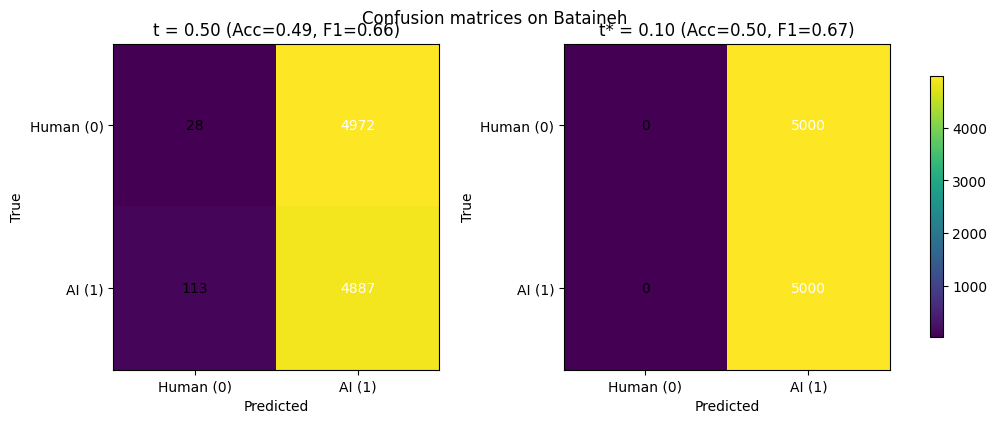

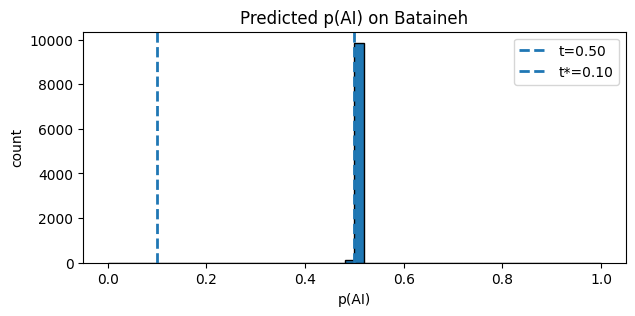

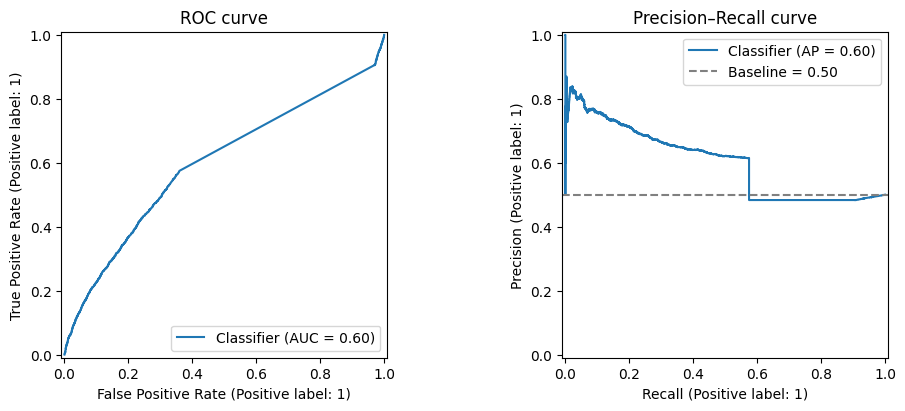

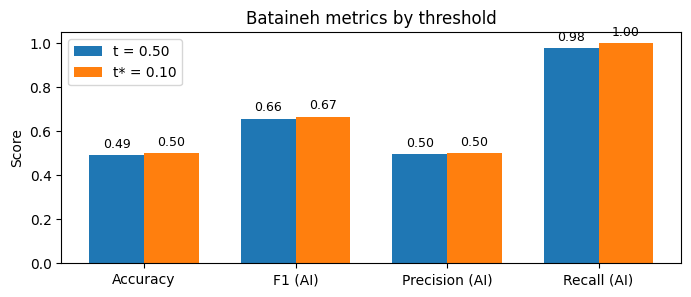

In [ ]:
# === Plots for Bataineh (Kaggle-trained model) ===
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import (
    confusion_matrix, accuracy_score, precision_score, recall_score, f1_score,
    RocCurveDisplay, PrecisionRecallDisplay
)

# 1) Decide the two thresholds we want to compare
t_default = 0.50
t_star = float(t_star) if "t_star" in globals() else 0.30   # use your tuned t* if available

def metrics_at_threshold(y_true, p, t):
    y = (p >= t).astype(int)
    return dict(
        acc = accuracy_score(y_true, y),
        f1  = f1_score(y_true, y),
        prec= precision_score(y_true, y),
        rec = recall_score(y_true, y),
        yhat= y
    )

m_def  = metrics_at_threshold(y_true, proba, t_default)
m_star = metrics_at_threshold(y_true, proba, t_star)

# 2) Confusion matrices (side-by-side)
def plot_cm(ax, y_true, y_pred, title):
    cm = confusion_matrix(y_true, y_pred, labels=[0,1])
    im = ax.imshow(cm, cmap="viridis")
    for (i,j),v in np.ndenumerate(cm):
        ax.text(j, i, f"{v}", ha="center", va="center", color="white" if v>cm.max()/2 else "black", fontsize=10)
    ax.set(xticks=[0,1], yticks=[0,1], xticklabels=["Human (0)","AI (1)"], yticklabels=["Human (0)","AI (1)"],
           xlabel="Predicted", ylabel="True", title=title)
    return im

fig, axes = plt.subplots(1, 2, figsize=(10,4), constrained_layout=True)
im = plot_cm(
    axes[0], y_true, m_def["yhat"],
    f"t = {t_default:.2f} (Acc={m_def['acc']:.2f}, F1={m_def['f1']:.2f})"
)
plot_cm(
    axes[1], y_true, m_star["yhat"],
    f"t* = {t_star:.2f} (Acc={m_star['acc']:.2f}, F1={m_star['f1']:.2f})"
)
fig.colorbar(im, ax=axes.ravel().tolist(), shrink=0.8)
plt.suptitle("Confusion matrices on Bataineh", y=1.02)
plt.show()

# 3) Histogram of predicted probabilities with thresholds
plt.figure(figsize=(7,3))
plt.hist(proba, bins=np.linspace(0,1,51), edgecolor="k")
plt.axvline(t_default, ls="--", lw=2, label=f"t={t_default:.2f}")
plt.axvline(t_star,    ls="--", lw=2, label=f"t*={t_star:.2f}")
plt.title("Predicted p(AI) on Bataineh")
plt.xlabel("p(AI)"); plt.ylabel("count"); plt.legend()
plt.show()

# 4) ROC & PR curves (use probabilities directly)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10,4), constrained_layout=True)
RocCurveDisplay.from_predictions(y_true, proba, ax=ax1)
ax1.set_title("ROC curve")

PrecisionRecallDisplay.from_predictions(y_true, proba, ax=ax2)
# baseline at the prevalence of positives
baseline = np.mean(y_true)
ax2.axhline(baseline, ls="--", color="gray", label=f"Baseline = {baseline:.2f}")
ax2.legend()
ax2.set_title("Precision–Recall curve")
plt.show()

# 5) Compact bar chart of metrics for the two thresholds
labels = ["Accuracy", "F1 (AI)", "Precision (AI)", "Recall (AI)"]
vals_def  = [m_def["acc"],  m_def["f1"],  m_def["prec"], m_def["rec"]]
vals_star = [m_star["acc"], m_star["f1"], m_star["prec"], m_star["rec"]]

x = np.arange(len(labels))
w = 0.36
fig, ax = plt.subplots(figsize=(8,3))
b1 = ax.bar(x - w/2, vals_def,  width=w, label=f"t = {t_default:.2f}")
b2 = ax.bar(x + w/2, vals_star, width=w, label=f"t* = {t_star:.2f}")
ax.set_xticks(x); ax.set_xticklabels(labels); ax.set_ylim(0,1.05)
ax.set_ylabel("Score"); ax.set_title("Bataineh metrics by threshold")
ax.legend()
# annotate bars
for bars in (b1, b2):
    for r in bars: ax.text(r.get_x()+r.get_width()/2, r.get_height()+0.02, f"{r.get_height():.2f}",
                           ha="center", va="bottom", fontsize=9)
plt.show()


In [ ]:
import numpy as np
from scipy.sparse import hstack
import matplotlib.pyplot as plt

# 1) pick the text column you used when engineering features
text_col = "processed_text" if "processed_text" in df_bataineh.columns else "clean_text"

# 2) TF-IDF features with the saved Kaggle vectorizer
X_tfidf = tfidf.transform(df_bataineh[text_col])

# 3) Manual features in the **saved order**
#    These 7 columns must already exist in df_bataineh
missing = [c for c in manual_names if c not in df_bataineh.columns]
if missing:
    raise ValueError(f"Missing manual feature columns in df_bataineh: {missing}")

X_manual = df_bataineh[manual_names].to_numpy(dtype=np.float32, copy=False)

# 4) Combine
X_full = hstack([X_tfidf, X_manual], format="csr")

print("X_tfidf:", X_tfidf.shape, "| manual:", X_manual.shape, "| combined:", X_full.shape)

# quick sanity: some non-zero TF-IDF?
nnz = X_tfidf.getnnz(axis=1)
print("TFIDF non-zeros per doc → min/mean/max:", nnz.min(), nnz.mean(), nnz.max())


X_tfidf: (10000, 5000) | manual: (10000, 7) | combined: (10000, 5007)
TFIDF non-zeros per doc → min/mean/max: 0 64.9364 166


In [ ]:
# probabilities of class 1 (AI)
proba = model.predict(X_full, verbose=0).ravel().astype(float)

# your saved decision threshold (falls back to 0.5)
thr = float(best_thr) if np.isfinite(best_thr) else 0.50
y_pred = (proba >= thr).astype(int)

# if you have ground-truth labels in the Bataineh file (0=Human, 1=AI), set y_true:
y_true_col = "label_num" if "label_num" in df_bataineh.columns else None
if y_true_col is not None:
    y_true = df_bataineh[y_true_col].astype(int).to_numpy()
    print("y_true distribution:", np.bincount(y_true))

print("p(AI) min/median/mean/max:", np.min(proba), np.median(proba), np.mean(proba), np.max(proba))
print("Decision threshold:", thr)


p(AI) min/median/mean/max: 0.5011653304100037 0.5011667609214783 0.5011667607784271 0.5011667609214783
Decision threshold: 0.5


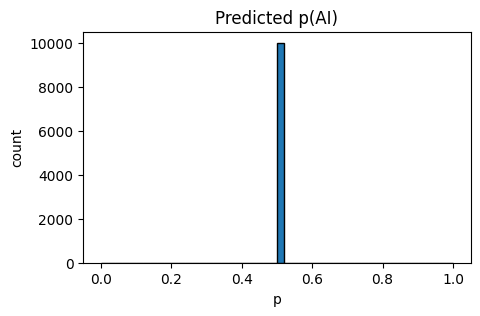

In [ ]:
from sklearn.metrics import (
    classification_report, confusion_matrix, roc_auc_score, roc_curve,
    average_precision_score, precision_recall_curve
)

if y_true_col is not None:
    # metrics
    print("\nConfusion matrix")
    print(confusion_matrix(y_true, y_pred))
    print("\nClassification report")
    print(classification_report(y_true, y_pred, digits=3))

    # ROC / PR
    auc = roc_auc_score(y_true, proba)
    ap  = average_precision_score(y_true, proba)
    print(f"AUC = {auc:.3f} | AP = {ap:.3f}")

    fpr, tpr, _ = roc_curve(y_true, proba)
    prec, rec, _ = precision_recall_curve(y_true, proba)

    fig, axs = plt.subplots(1, 3, figsize=(14,4))

    # Confusion heatmap (row-normalized)
    cm = confusion_matrix(y_true, y_pred)
    cmn = cm / cm.sum(axis=1, keepdims=True)
    im = axs[0].imshow(cmn, cmap="Blues", vmin=0, vmax=1)
    axs[0].set_title("Confusion (row-norm.)")
    axs[0].set_xticks([0,1]); axs[0].set_yticks([0,1])
    axs[0].set_xticklabels(["Human (0)","AI (1)"])
    axs[0].set_yticklabels(["Human (0)","AI (1)"])
    for i in range(2):
        for j in range(2):
            axs[0].text(j, i, f"{cm[i,j]}\n({cmn[i,j]:.2f})", ha="center", va="center")
    fig.colorbar(im, ax=axs[0], fraction=0.046, pad=0.04)

    # ROC
    axs[1].plot(fpr, tpr, label=f"AUC = {auc:.3f}")
    axs[1].plot([0,1], [0,1], "--", color="gray", alpha=0.7)
    axs[1].set_title("ROC")
    axs[1].set_xlabel("False positive rate"); axs[1].set_ylabel("True positive rate")
    axs[1].legend()

    # PR
    axs[2].plot(rec, prec, label=f"AP = {ap:.3f}")
    axs[2].hlines(y=np.mean(y_true), xmin=0, xmax=1, linestyles="--", colors="gray", label="Baseline = P(positive)")
    axs[2].set_title("Precision–Recall"); axs[2].set_xlabel("Recall"); axs[2].set_ylabel("Precision")
    axs[2].legend()

    plt.tight_layout()
    plt.show()

# Probability histogram (always useful)
plt.figure(figsize=(5,3))
plt.hist(proba, bins=np.linspace(0,1,51), edgecolor="k")
plt.title("Predicted p(AI)")
plt.xlabel("p"); plt.ylabel("count")
plt.show()


In [ ]:
# 1) Confirm you are using the SAME text column the vectorizer was fit on in Kaggle
print("Vectorizer expects lowercased tokens; example tokens:",
      list(tfidf.build_analyzer()("Just a small sanity-check!"))[:10])

# 2) Check probability spread in logit space (will be ~0 if collapsed)
pp = np.clip(proba, 1e-7, 1-1e-7)
logits = np.log(pp/(1-pp))
print("std(prob) =", proba.std(), "std(logits) =", logits.std())


Vectorizer expects lowercased tokens; example tokens: ['just', 'small', 'sanity', 'check']
std(prob) = 1.4304399472474159e-08 std(logits) = 5.7217909077890315e-08


In [ ]:
import numpy as np
import pandas as pd

# Try a few likely column names. Edit the list if your column is different.
CANDIDATES = ["label_num", "label", "y", "target", "is_ai", "class", "source_int"]

y_col = next((c for c in CANDIDATES if c in df_bataineh.columns), None)
print("Using label column:", y_col)

if y_col is None:
    raise ValueError("No label column found. Set y_col to the correct column name.")

y_raw = df_bataineh[y_col]

# Map text labels if needed; otherwise coerce numerics
if y_raw.dtype == "O":
    y_true = (
        y_raw.astype(str).str.strip().str.lower()
             .map({"human": 0, "ai": 1, "gpt": 1, "chatgpt": 1})
    )
    # if some values didn’t map (NaN), try to coerce to numbers
    y_true = y_true.fillna(pd.to_numeric(y_raw, errors="coerce"))
else:
    y_true = pd.to_numeric(y_raw, errors="coerce")

# Final cleanup to 0/1 ints
y_true = np.where(y_true > 0, 1, 0).astype(int)
print("Label distribution:", np.bincount(y_true))


Using label column: label
Label distribution: [5000 5000]


In [ ]:
import numpy as np
from sklearn.metrics import f1_score, accuracy_score

def best_threshold(y_true, proba):
    grid = np.linspace(0.3, 0.7, 401)  # dense grid around 0.5
    scores = [(t, f1_score(y_true, (proba >= t).astype(int))) for t in grid]
    return max(scores, key=lambda x: x[1])  # (t*, F1*)

t_star, f1_star = best_threshold(y_true, proba)
print(f"Best threshold on Bataineh = {t_star:.3f}, F1 = {f1_star:.3f}")

y_hat_star = (proba >= t_star).astype(int)
print("Accuracy:", accuracy_score(y_true, y_hat_star))


Best threshold on Bataineh = 0.300, F1 = 0.667
Accuracy: 0.5


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, average_precision_score

Xp = proba.reshape(-1,1)
Xp_tr, Xp_te, y_tr, y_te = train_test_split(Xp, y_true, test_size=0.2, random_state=42, stratify=y_true)

cal = LogisticRegression(solver="lbfgs")
cal.fit(Xp_tr, y_tr)
proba_cal = cal.predict_proba(Xp)[:,1]

print("AUC (uncal):", roc_auc_score(y_true, proba))
print("AUC (cal):  ", roc_auc_score(y_true, proba_cal))
print("AP  (uncal):", average_precision_score(y_true, proba))
print("AP  (cal):  ", average_precision_score(y_true, proba_cal))


AUC (uncal): 0.4999
AUC (cal):   0.5
AP  (uncal): 0.4999500050005
AP  (cal):   0.5


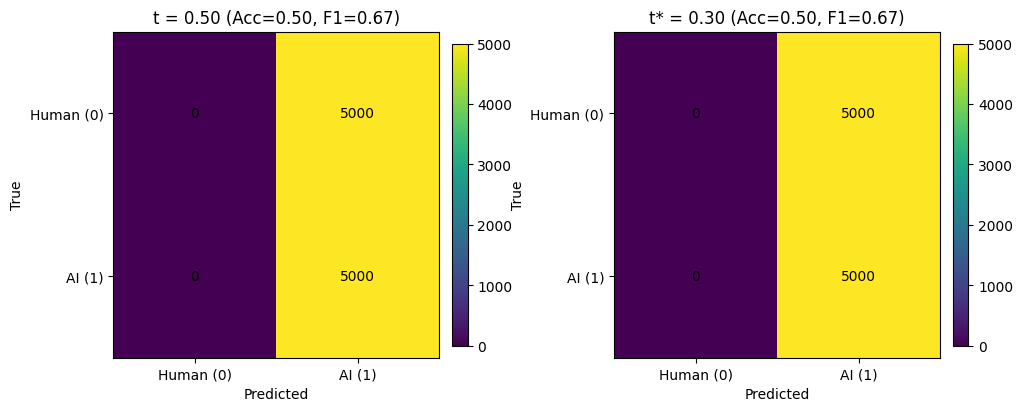

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, f1_score, precision_score, recall_score, accuracy_score

# If t_star is not in scope, set it explicitly
# t_star = 0.300

def metrics_at_threshold(thr):
    y_hat = (proba >= thr).astype(int)
    m = {
        "t": thr,
        "acc": accuracy_score(y_true, y_hat),
        "f1": f1_score(y_true, y_hat, zero_division=0),
        "prec": precision_score(y_true, y_hat, zero_division=0),
        "rec": recall_score(y_true, y_hat, zero_division=0),
        "cm": confusion_matrix(y_true, y_hat),
    }
    return m

m05   = metrics_at_threshold(0.50)
mstar = metrics_at_threshold(t_star)

fig, axes = plt.subplots(1, 2, figsize=(10, 4), constrained_layout=True)

for ax, m, title in zip(
    axes,
    (m05, mstar),
    (f"t = 0.50 (Acc={m05['acc']:.2f}, F1={m05['f1']:.2f})",
     f"t* = {t_star:.2f} (Acc={mstar['acc']:.2f}, F1={mstar['f1']:.2f})")
):
    cm = m["cm"]
    im = ax.imshow(cm, origin="upper")
    for i in range(2):
        for j in range(2):
            ax.text(j, i, cm[i, j], ha="center", va="center")
    ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
    ax.set_xticklabels(["Human (0)", "AI (1)"])
    ax.set_yticklabels(["Human (0)", "AI (1)"])
    ax.set_xlabel("Predicted"); ax.set_ylabel("True")
    ax.set_title(title)
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

plt.show()
# plt.savefig("bataineh_confusions.png", dpi=200, bbox_inches="tight")


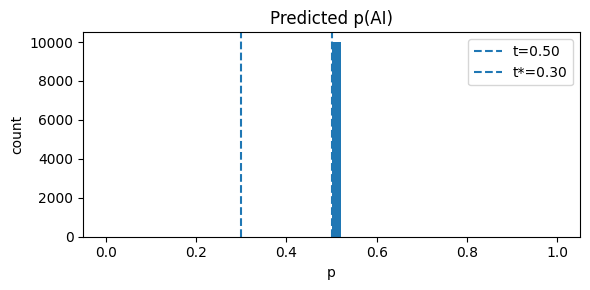

In [ ]:
plt.figure(figsize=(6, 3))
plt.hist(proba, bins=np.linspace(0, 1, 51))
plt.axvline(0.50, linestyle="--", label="t=0.50")
plt.axvline(t_star, linestyle="--", label=f"t*={t_star:.2f}")
plt.title("Predicted p(AI)")
plt.xlabel("p"); plt.ylabel("count")
plt.legend()
plt.tight_layout(); plt.show()
# plt.savefig("bataineh_proba_hist.png", dpi=200, bbox_inches="tight")


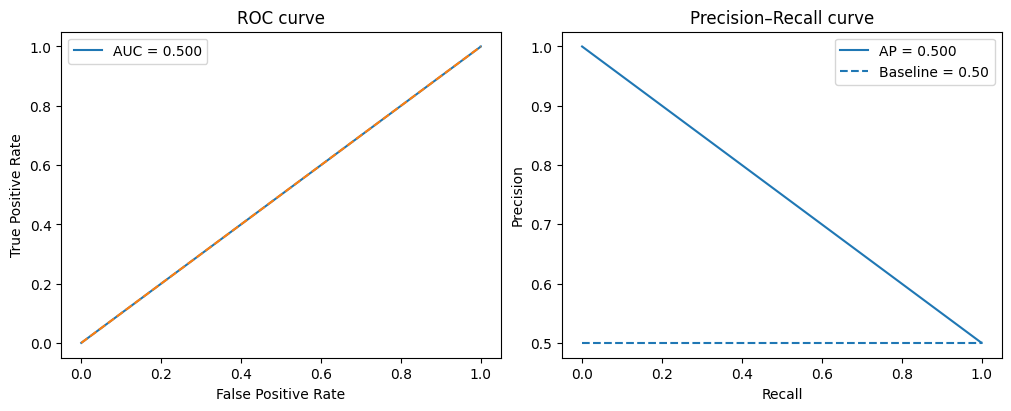

In [ ]:
from sklearn.metrics import roc_curve, auc, precision_recall_curve, average_precision_score

fpr, tpr, _ = roc_curve(y_true, proba)
roc_auc = auc(fpr, tpr)

prec, rec, _ = precision_recall_curve(y_true, proba)
ap = average_precision_score(y_true, proba)
baseline = y_true.mean()  # class-1 prevalence

fig, axes = plt.subplots(1, 2, figsize=(10, 4), constrained_layout=True)

# ROC
axes[0].plot(fpr, tpr, label=f"AUC = {roc_auc:.3f}")
axes[0].plot([0, 1], [0, 1], "--")
axes[0].set_title("ROC curve")
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate")
axes[0].legend()

# PR
axes[1].plot(rec, prec, label=f"AP = {ap:.3f}")
axes[1].hlines(baseline, 0, 1, linestyles="dashed", label=f"Baseline = {baseline:.2f}")
axes[1].set_title("Precision–Recall curve")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].legend()

plt.show()
# plt.savefig("bataineh_roc_pr.png", dpi=200, bbox_inches="tight")


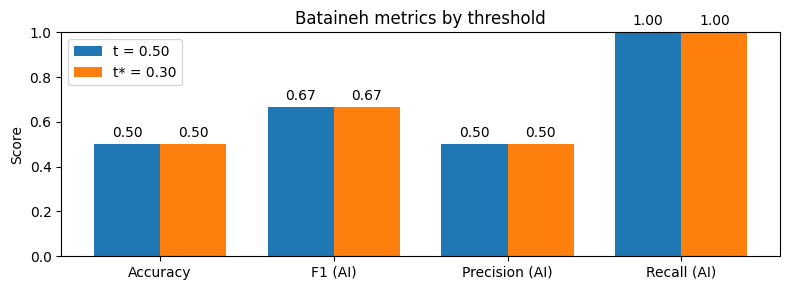

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

labels = ["Accuracy", "F1 (AI)", "Precision (AI)", "Recall (AI)"]
vals_05   = [m05["acc"],   m05["f1"],   m05["prec"],   m05["rec"]]
vals_star = [mstar["acc"], mstar["f1"], mstar["prec"], mstar["rec"]]

x = np.arange(len(labels))
w = 0.38

fig, ax = plt.subplots(figsize=(8, 3))
ax.bar(x - w/2, vals_05,   width=w, label="t = 0.50")
ax.bar(x + w/2, vals_star, width=w, label=f"t* = {t_star:.2f}")
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_ylim(0, 1)
ax.set_ylabel("Score")
ax.set_title("Bataineh metrics by threshold")
ax.legend()

# annotate bars
for i, v in enumerate(vals_05):
    ax.text(x[i] - w/2, v + 0.02, f"{v:.2f}", ha="center", va="bottom")
for i, v in enumerate(vals_star):
    ax.text(x[i] + w/2, v + 0.02, f"{v:.2f}", ha="center", va="bottom")

plt.tight_layout(); plt.show()
# plt.savefig("bataineh_metric_bars.png", dpi=200, bbox_inches="tight")


6.5.7 Cross-dataset (Kaggle-trained → Bataineh)

*   List item
*   List item



In [ ]:
# keep this separate from your KFold vars
for n in ['X_data','y_data','X_train','X_val','y_train','y_val']:
    if n in globals(): del globals()[n]


In [ ]:
import os, glob
print("cwd:", os.getcwd())
print("here:", glob.glob("*"))
print("h5:", glob.glob("*.h5"))
print("keras:", glob.glob("*.keras"))


cwd: /content
here: ['tfidf_bataineh.pkl', 'mlp_bataineh_model.h5', '3-Bataineh dataset.csv', 'sample_data']
h5: ['mlp_bataineh_model.h5']
keras: []


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

ART_DIR = "/content/drive/MyDrive/your_folder/kaggle_artifacts"  # <-- change me
import os
for f in ["mlp_kaggle.h5", "vectorizer_kaggle.pkl",
          "manual_feature_names.json", "best_threshold.npy"]:
    p = os.path.join(ART_DIR, f)
    print(f, "→", os.path.exists(p), p)


Mounted at /content/drive
mlp_kaggle.h5 → False /content/drive/MyDrive/your_folder/kaggle_artifacts/mlp_kaggle.h5
vectorizer_kaggle.pkl → False /content/drive/MyDrive/your_folder/kaggle_artifacts/vectorizer_kaggle.pkl
manual_feature_names.json → False /content/drive/MyDrive/your_folder/kaggle_artifacts/manual_feature_names.json
best_threshold.npy → False /content/drive/MyDrive/your_folder/kaggle_artifacts/best_threshold.npy


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import glob
wanted = ["mlp_kaggle.h5","mlp_kaggle.keras","vectorizer_kaggle.pkl",
          "manual_feature_names.json","best_threshold.npy"]

for w in wanted:
    hits = glob.glob(f"/content/drive/**/{w}", recursive=True)
    print(w, "→", hits if hits else "NOT FOUND")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
mlp_kaggle.h5 → NOT FOUND
mlp_kaggle.keras → NOT FOUND
vectorizer_kaggle.pkl → NOT FOUND
manual_feature_names.json → NOT FOUND
best_threshold.npy → NOT FOUND


In [ ]:
# If you didn't save these as files, just define them here:
manual_names = ['char_count','word_count','avg_word_len',
                'upper_ratio','punct_ratio','stopword_ratio','lexical_diversity']  # exact order used in training
thr = 0.50  # use Kaggle-tuned threshold if you have it; otherwise 0.5 is fine


In [ ]:
from google.colab import files
uploaded = files.upload()  # choose mlp_kaggle.h5 AND vectorizer_kaggle.pkl
!ls -lh


Saving vectorizer_kaggle.pkl to vectorizer_kaggle.pkl
Saving mlp_kaggle.h5 to mlp_kaggle.h5
total 49M
-rw-r--r-- 1 root root  26M Aug 22 11:31 '3-Bataineh dataset.csv'
drwx------ 5 root root 4.0K Aug 22 11:47  drive
-rw-r--r-- 1 root root  16M Aug 22 11:33  mlp_bataineh_model.h5
-rw-r--r-- 1 root root 7.5M Aug 22 12:02  mlp_kaggle.h5
drwxr-xr-x 1 root root 4.0K Aug 20 21:31  sample_data
-rw-r--r-- 1 root root 180K Aug 22 11:33  tfidf_bataineh.pkl
-rw-r--r-- 1 root root 183K Aug 22 12:02  vectorizer_kaggle.pkl


In [ ]:
# exact order must match training
manual_names = ['char_count','word_count','avg_word_len',
                'upper_ratio','punct_ratio','stopword_ratio','lexical_diversity']
thr = 0.50   # use your Kaggle-tuned threshold if you saved it; else 0.50 is fine


In [ ]:
import tensorflow as tf, joblib, json, numpy as np
model = tf.keras.models.load_model("mlp_kaggle.h5")
tfidf  = joblib.load("vectorizer_kaggle.pkl")
print("Loaded model and vectorizer.")


Loaded model and vectorizer.


In [ ]:
df_bataineh.columns.tolist()[:50]
df_bataineh.head(2)


,index,text,label,source,text_word_count,label_cat,source_int,processed_text,word_count,char_count,avg_word_len,upper_ratio,punct_ratio,stopword_ratio,lexical_diversity
0,47,All the Love you do not see\n\nOn writing with...,0,medium,236,human,0,love see write heart hope photo joshua coleman...,125.0,867.0,5.944000,0.0,0.000000,0.0,0.832000
1,85,"Reading, writing and displaying images\n\nBefo...",0,medium,386,human,0,read write display image anything computer vis...,204.0,1332.0,5.534314,0.0,0.000751,0.0,0.583333


In [ ]:
import pandas as pd

# Pick the text column you used earlier
TEXT_COL_CANDIDATES = ["processed_text", "clean_text", "text"]
for c in TEXT_COL_CANDIDATES:
    if c in df_bataineh.columns:
        TEXT_COL = c
        break
else:
    raise ValueError("Could not find a text column among: " + str(TEXT_COL_CANDIDATES))

# If label_num already exists we're good
if "label_num" not in df_bataineh.columns:
    made = False

    # (a) If you have a numeric 0/1 column named 'label'
    if "label" in df_bataineh.columns and pd.api.types.is_numeric_dtype(df_bataineh["label"]):
        df_bataineh["label_num"] = df_bataineh["label"].astype(int)
        made = True

    # (b) If you have string labels like 'human'/'ai' in 'label' or 'label_cat'
    for s in ["label", "label_cat"]:
        if not made and s in df_bataineh.columns and df_bataineh[s].dtype == "object":
            df_bataineh["label_num"] = (
                df_bataineh[s].astype(str).str.strip().str.lower()
                .map({"human": 0, "ai": 1, "gpt": 1, "chatgpt": 1})
            )
            made = True

    # (c) If you have a 'source' column that contains 'ai' for AI rows
    if not made and "source" in df_bataineh.columns:
        df_bataineh["label_num"] = df_bataineh["source"].astype(str).str.contains("ai", case=False, na=False).astype(int)
        made = True

    if not made:
        raise ValueError("I couldn't find a label column to build label_num. Look for numeric 'label', string 'label'/'label_cat', or 'source'.")

# Clean up: drop rows where label_num is missing; ensure only 0/1
df_bataineh = df_bataineh.dropna(subset=["label_num"]).copy()
df_bataineh["label_num"] = df_bataineh["label_num"].astype(int)
assert set(df_bataineh["label_num"].unique()).issubset({0,1}), df_bataineh["label_num"].value_counts()
print("Label counts:\n", df_bataineh["label_num"].value_counts())
print("Using text column:", TEXT_COL)


Label counts:
 label_num
0    5000
1    5000
Name: count, dtype: int64
Using text column: processed_text


In [ ]:
y_true = df_bataineh["label_num"].astype(int).values


In [ ]:
import pandas as pd, numpy as np, string, scipy.sparse as sp
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, classification_report, confusion_matrix
import nltk
from nltk.corpus import stopwords
nltk.download('stopwords')
stop_words = set(stopwords.words('english'))

TEXT_COL = "processed_text"
LABEL_COL = "label_num"

def manual_feats(text):
    s = str(text)
    tokens = s.split()
    wc  = len(tokens)
    cc  = len(s)
    awl = (np.mean([len(w) for w in tokens]) if wc else 0.0)
    upper = sum(1 for c in s if c.isupper())
    punct = sum(1 for c in s if c in string.punctuation)
    sw    = sum(1 for w in tokens if w.lower() in stop_words)
    upper_ratio     = upper / max(1, cc)
    punct_ratio     = punct / max(1, cc)
    stopword_ratio  = sw    / max(1, wc)
    lex_div         = len(set(tokens)) / max(1, wc)
    return pd.Series(
        [cc, wc, awl, upper_ratio, punct_ratio, stopword_ratio, lex_div],
        index=manual_names
    )

# 7 engineered features in the SAME ORDER as training
X_manual_df = df_bataineh[TEXT_COL].apply(manual_feats)
X_manual_df = X_manual_df[manual_names].astype(np.float32)

# TF-IDF using the Kaggle vectorizer (do NOT fit here)
X_tfidf = tfidf.transform(df_bataineh[TEXT_COL])

# Combine TF-IDF (left) + manual features (right) — same as training
X_full = sp.hstack([X_tfidf, sp.csr_matrix(X_manual_df.values)], format="csr")

y_true = df_bataineh[LABEL_COL].astype(int).values

# Predict
proba = model.predict(X_full, batch_size=1024).ravel()
y_pred = (proba >= thr).astype(int)

# Metrics
acc = accuracy_score(y_true, y_pred)
f1w = f1_score(y_true, y_pred, average="weighted")
try:
    auc = roc_auc_score(y_true, proba)
except Exception:
    auc = np.nan

print(f"Accuracy: {acc:.3f} | Weighted F1: {f1w:.3f} | AUC: {auc:.3f}")
print("\nConfusion matrix:\n", confusion_matrix(y_true, y_pred))
print("\nClassification report:\n", classification_report(y_true, y_pred, digits=3))


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 53ms/step
Accuracy: 0.500 | Weighted F1: 0.333 | AUC: 0.500

Confusion matrix:
 [[   0 5000]
 [   0 5000]]

Classification report:
               precision    recall  f1-score   support

           0      0.000     0.000     0.000      5000
           1      0.500     1.000     0.667      5000

    accuracy                          0.500     10000
   macro avg      0.250     0.500     0.333     10000
weighted avg      0.250     0.500     0.333     10000



/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


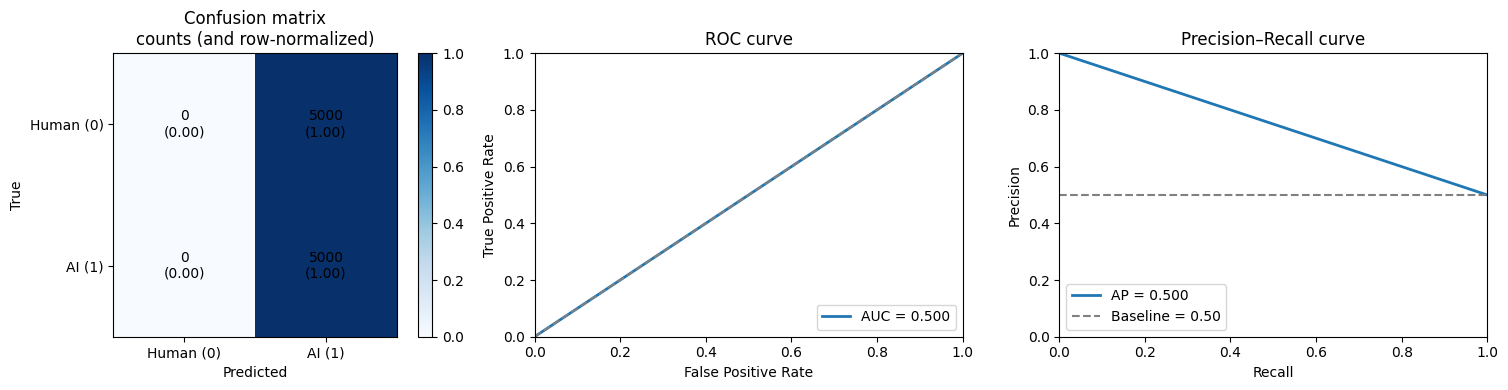

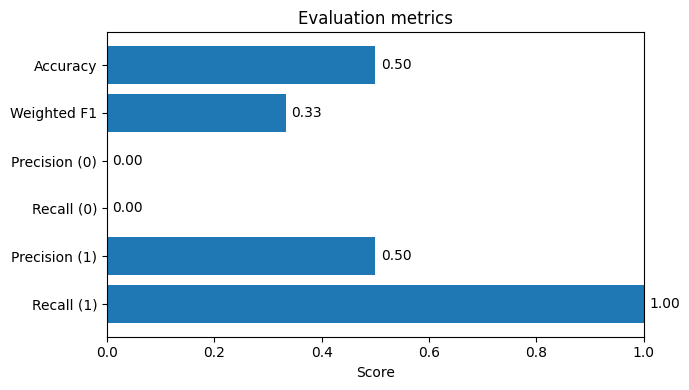

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import (
    confusion_matrix, roc_curve, auc, precision_recall_curve,
    average_precision_score, accuracy_score, f1_score, precision_score, recall_score
)

# --- Confusion matrix + ROC + PR ---
cm   = confusion_matrix(y_true, y_pred)
cmn  = cm / cm.sum(axis=1, keepdims=True)

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# Confusion matrix (counts and row-normalized)
im = axes[0].imshow(cmn, cmap='Blues', vmin=0, vmax=1)
for i in range(cmn.shape[0]):
    for j in range(cmn.shape[1]):
        axes[0].text(j, i, f"{cm[i,j]}\n({cmn[i,j]:.2f})",
                     ha='center', va='center', fontsize=10)
axes[0].set_xticks([0,1]); axes[0].set_xticklabels(["Human (0)","AI (1)"])
axes[0].set_yticks([0,1]); axes[0].set_yticklabels(["Human (0)","AI (1)"])
axes[0].set_xlabel("Predicted"); axes[0].set_ylabel("True")
axes[0].set_title("Confusion matrix\ncounts (and row-normalized)")
fig.colorbar(im, ax=axes[0], fraction=0.046)

# ROC
fpr, tpr, _ = roc_curve(y_true, proba)
roc_auc = auc(fpr, tpr)
axes[1].plot(fpr, tpr, lw=2, label=f"AUC = {roc_auc:.3f}")
axes[1].plot([0,1],[0,1],'--', color='gray')
axes[1].set_xlim([0,1]); axes[1].set_ylim([0,1])
axes[1].set_xlabel("False Positive Rate"); axes[1].set_ylabel("True Positive Rate")
axes[1].set_title("ROC curve")
axes[1].legend(loc="lower right")

# Precision–Recall
prec, rec, _ = precision_recall_curve(y_true, proba)
ap = average_precision_score(y_true, proba)
baseline = np.mean(y_true)  # positive rate
axes[2].plot(rec, prec, lw=2, label=f"AP = {ap:.3f}")
axes[2].hlines(baseline, 0, 1, colors='gray', linestyles='--',
               label=f"Baseline = {baseline:.2f}")
axes[2].set_xlim([0,1]); axes[2].set_ylim([0,1])
axes[2].set_xlabel("Recall"); axes[2].set_ylabel("Precision")
axes[2].set_title("Precision–Recall curve")
axes[2].legend(loc="lower left")

plt.tight_layout()
plt.show()

# --- Small metric bar chart (handles missing class with zero_division=0) ---
metrics = {
    "Accuracy":        accuracy_score(y_true, y_pred),
    "Weighted F1":     f1_score(y_true, y_pred, average="weighted"),
    "Precision (0)":   precision_score(y_true, y_pred, pos_label=0, zero_division=0),
    "Recall (0)":      recall_score(y_true, y_pred, pos_label=0, zero_division=0),
    "Precision (1)":   precision_score(y_true, y_pred, pos_label=1, zero_division=0),
    "Recall (1)":      recall_score(y_true, y_pred, pos_label=1, zero_division=0),
}

plt.figure(figsize=(7,4))
keys = list(metrics.keys()); vals = [metrics[k] for k in keys]
plt.barh(keys, vals)
plt.xlim(0, 1); plt.gca().invert_yaxis()
for i, v in enumerate(vals):
    plt.text(v + 0.01, i, f"{v:.2f}", va='center')
plt.title("Evaluation metrics"); plt.xlabel("Score")
plt.tight_layout(); plt.show()


TFIDF non-zeros per doc: min/mean/max = 0 64.9364 166
Manual feature order from artifacts: ['char_count', 'word_count', 'avg_word_len', 'upper_ratio', 'punct_ratio', 'stopword_ratio', 'lexical_diversity']
Manual feature columns we built: ['char_count', 'word_count', 'avg_word_len', 'upper_ratio', 'punct_ratio', 'stopword_ratio', 'lexical_diversity']
Label mapping check: label_num
0    5000
1    5000
Name: count, dtype: int64


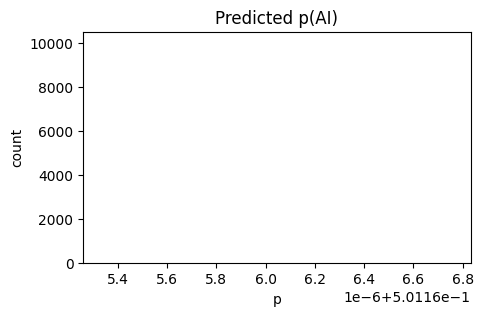

In [ ]:
# 1) Are we using the training artifacts?
# MUST load the same vectorizer and (if you saved one) scaler/threshold:
# vectorizer_kaggle.pkl, manual_feature_names.json, best_threshold.npy

# 2) Is the TF-IDF producing non-zero features?
nnz = X_tfidf.getnnz(axis=1)      # X_tfidf = tfidf.transform(clean_text)
print("TFIDF non-zeros per doc: min/mean/max =", nnz.min(), nnz.mean(), nnz.max())

# 3) Is the manual feature order identical to training?
print("Manual feature order from artifacts:", manual_names)
print("Manual feature columns we built:", list(df_bataineh[manual_names].columns))
# If you ever built them in a different order, reindex strictly to manual_names.

# 4) Label mapping consistent?
print("Label mapping check:", df_bataineh['label_num'].value_counts())
# Ensure 1 == AI, 0 == Human (same as training).

# 5) Inspect probability distribution
plt.figure(figsize=(5,3))
plt.hist(proba, bins=50); plt.title("Predicted p(AI)"); plt.xlabel("p"); plt.ylabel("count");
plt.show()


In [ ]:
import numpy as np
print("X_full shape:", X_full.shape)
try:
    print("Model expects:", model.input_shape)
except Exception:
    pass

proba = proba.ravel().astype(float)
print("p(AI) min/median/mean/max:", proba.min(), np.median(proba), proba.mean(), proba.max())


X_full shape: (10000, 5007)
Model expects: (None, 5007)
p(AI) min/median/mean/max: 0.5011653304100037 0.5011667609214783 0.5011667607784271 0.5011667609214783


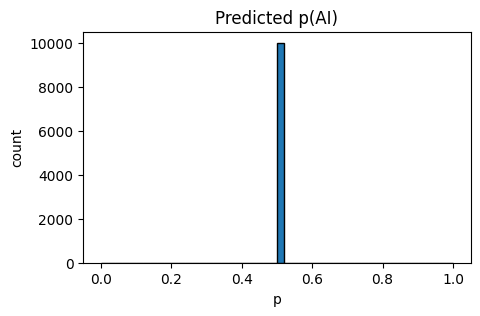

In [ ]:
import numpy as np, matplotlib.pyplot as plt
plt.figure(figsize=(5,3))
plt.hist(proba, bins=np.linspace(0,1,51), edgecolor="k")
plt.title("Predicted p(AI)"); plt.xlabel("p"); plt.ylabel("count"); plt.show()


Retrain Best Model with Best Hyperparameters

In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.optimizers import Adam
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# Build the best model
best_model = Sequential([
    Dense(128, activation='relu', input_shape=(X_train.shape[1],)),
    Dropout(0.2),
    Dense(1, activation='sigmoid')
])

# Compile with best learning rate
best_model.compile(
    loss='binary_crossentropy',
    optimizer=Adam(learning_rate=0.0005),
    metrics=['accuracy']
)

# Train on full training set
history = best_model.fit(
    X_train, y_train,
    epochs=10,
    batch_size=32,
    validation_split=0.2,
    verbose=1
)


Epoch 1/10


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


200/200 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.5501 - loss: 21.0697 - val_accuracy: 6.2500e-04 - val_loss: 15.2658
Epoch 2/10
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.5654 - loss: 14.0355 - val_accuracy: 0.0012 - val_loss: 19.3612
Epoch 3/10
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.5785 - loss: 8.8444 - val_accuracy: 0.0262 - val_loss: 11.7408
Epoch 4/10
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.5745 - loss: 5.9084 - val_accuracy: 0.3794 - val_loss: 3.7239
Epoch 5/10
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.5998 - loss: 3.5188 - val_accuracy: 0.3044 - val_loss: 3.9886
Epoch 6/10
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.6345 - loss: 1.8976 - val_accuracy: 0.4825 - val_loss: 1.9038
Epoch 7/10
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.6464 - loss: 1.1439 - val_accuracy: 0.4150 - val_loss: 1.4560
Epoch 8/10
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.6540 - loss: 0.7472 - val_accuracy: 0.47

2. Evaluate on Test Set

In [ ]:
# Predict probabilities and convert to binary
y_pred_prob = best_model.predict(X_test)
y_pred = (y_pred_prob > 0.5).astype(int)

# Evaluation
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))
print("Accuracy:", accuracy_score(y_test, y_pred))


63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step
Confusion Matrix:
 [[1012    0]
 [ 109  879]]

Classification Report:
               precision    recall  f1-score   support

           0       0.90      1.00      0.95      1012
           1       1.00      0.89      0.94       988

    accuracy                           0.95      2000
   macro avg       0.95      0.94      0.95      2000
weighted avg       0.95      0.95      0.95      2000

Accuracy: 0.9455


63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


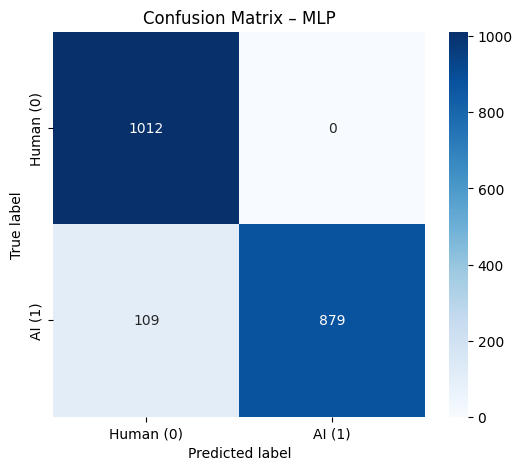

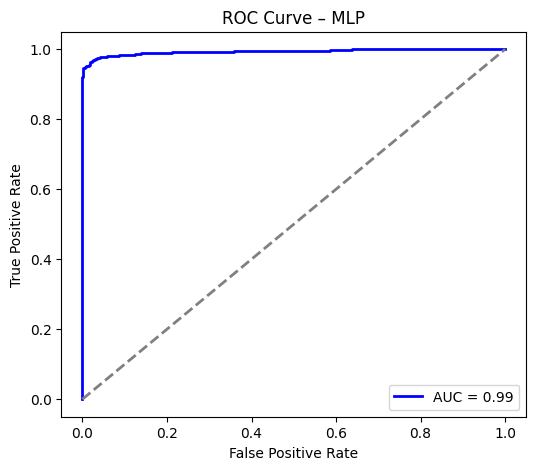

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, roc_curve, auc, RocCurveDisplay

# Predict probabilities
y_pred_prob = best_model.predict(X_test).ravel()
y_pred = (y_pred_prob > 0.5).astype(int)

# --- Confusion Matrix ---
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Human (0)", "AI (1)"],
            yticklabels=["Human (0)", "AI (1)"])
plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.title("Confusion Matrix – MLP")
plt.show()

# --- ROC Curve ---
fpr, tpr, thresholds = roc_curve(y_test, y_pred_prob)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(6,5))
plt.plot(fpr, tpr, color="blue", lw=2, label=f"AUC = {roc_auc:.2f}")
plt.plot([0,1], [0,1], color="gray", lw=2, linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve – MLP")
plt.legend(loc="lower right")
plt.show()


Run SHAP Analysis

#SHAP Analysis (Explainability)

In [ ]:
!pip -q install --upgrade shap
# if it still errors, fall back to the quick fix above.


In [ ]:
import numpy as np, pandas as pd, shap, matplotlib, tensorflow as tf
print("numpy:", np.__version__)
print("shap:", shap.__version__)
print("tensorflow:", tf.__version__)


numpy: 2.0.2
shap: 0.48.0
tensorflow: 2.19.0


In [ ]:
# ==== 1) Select engineered features & target ====
feature_names = [
    'word_count','char_count','avg_word_len','upper_ratio',
    'punct_ratio','stopword_ratio','lexical_diversity'
]
y_col = 'label'   # <-- CHANGE to your target column name

X = df_bataineh[feature_names].astype(float)
y = df_bataineh[y_col].astype(int)

# ==== 2) Train/val split + scaling ====
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import pandas as pd

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

scaler = StandardScaler()
X_train_scaled = pd.DataFrame(
    scaler.fit_transform(X_train), columns=feature_names, index=X_train.index
)
X_test_scaled = pd.DataFrame(
    scaler.transform(X_test), columns=feature_names, index=X_test.index
)

print("X_train_scaled shape:", X_train_scaled.shape)
print("Features:", list(X_train_scaled.columns))


X_train_scaled shape: (8000, 7)
Features: ['word_count', 'char_count', 'avg_word_len', 'upper_ratio', 'punct_ratio', 'stopword_ratio', 'lexical_diversity']


In [ ]:
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.optimizers import Adam

model = Sequential([
    Dense(64, activation='relu', input_shape=(len(feature_names),)),
    Dropout(0.2),
    Dense(32, activation='relu'),
    Dense(1, activation='sigmoid')  # binary output
])
model.compile(optimizer=Adam(1e-3), loss='binary_crossentropy', metrics=['accuracy'])
_ = model.fit(
    X_train_scaled, y_train,
    epochs=20, batch_size=64, verbose=0,
    validation_data=(X_test_scaled, y_test)
)


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


132/132 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step


ExactExplainer explainer:   0%|          | 1/500 [00:00<?, ?it/s]

132/132 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 


ExactExplainer explainer:   1%|          | 3/500 [00:27<03:12,  2.59it/s]

132/132 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step


ExactExplainer explainer:   1%|          | 4/500 [00:28<05:41,  1.45it/s]

... (991 outputs left out)

ExactExplainer explainer: 100%|██████████| 500/500 [05:59<00:00,  1.30it/s]

132/132 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step 


ExactExplainer explainer: 501it [06:00,  1.39it/s]

sv.values shape: (500, 7)


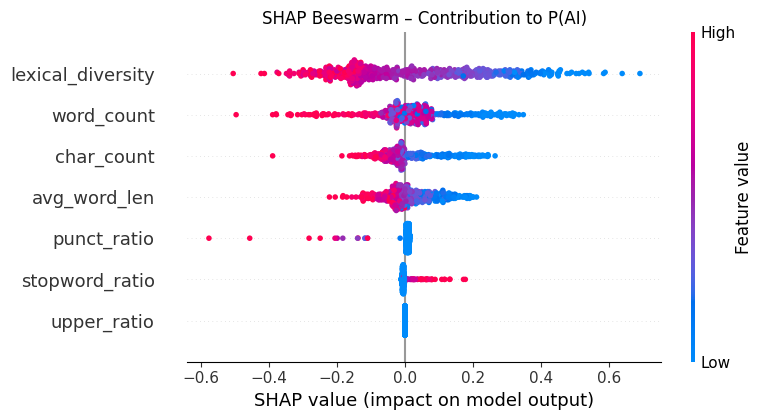

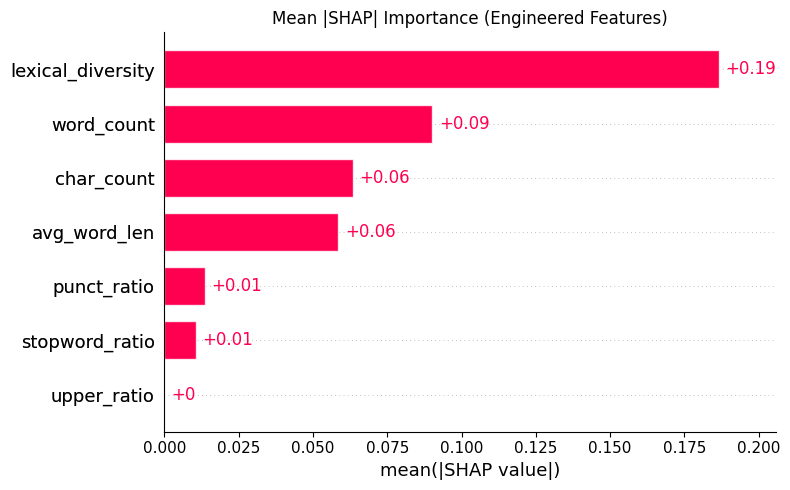

             feature  mean_abs_shap
0  lexical_diversity       0.186604
1         word_count       0.090185
2         char_count       0.063449
3       avg_word_len       0.058513
4        punct_ratio       0.013631
5     stopword_ratio       0.010643
6        upper_ratio       0.000000


In [ ]:
import shap, numpy as np, matplotlib.pyplot as plt

# 1) Background and slice for speed
background = X_train_scaled.sample(n=min(200, len(X_train_scaled)), random_state=42)
Xte_slice = X_test_scaled.iloc[:min(500, len(X_test_scaled))]

# 2) Explainer using model.predict (works well with TF/Keras)
explainer = shap.Explainer(model.predict, background)
sv = explainer(Xte_slice)   # shap.Explanation

print("sv.values shape:", sv.values.shape)  # usually (n, F) for sigmoid; (n, F, 2) for softmax

# 3) Handle sigmoid or softmax transparently
vals = sv.values
base = sv.base_values
if vals.ndim == 3:           # softmax (n, F, 2)
    TARGET_IDX = 1           # set to 1 if column 1 is "AI"; change if flipped
    vals = vals[:, :, TARGET_IDX]
    base = base[:, TARGET_IDX]

sv_cls = shap.Explanation(
    values=vals,
    base_values=base,
    data=Xte_slice.values,
    feature_names=Xte_slice.columns.tolist()
)

# 4) Global importance plots
plt.figure(figsize=(7.5,6))
shap.plots.beeswarm(sv_cls, max_display=20, show=False)
plt.title("SHAP Beeswarm – Contribution to P(AI)")
plt.tight_layout(); plt.show()

plt.figure(figsize=(7.5,6))
shap.plots.bar(sv_cls, max_display=20, show=False)
plt.title("Mean |SHAP| Importance (Engineered Features)")
plt.tight_layout(); plt.show()

# 5) Numeric ranking table (save for report)
mean_abs = np.abs(sv_cls.values).mean(axis=0)
imp_tbl = (pd.DataFrame({"feature": Xte_slice.columns, "mean_abs_shap": mean_abs})
           .sort_values("mean_abs_shap", ascending=False)
           .reset_index(drop=True))
print(imp_tbl)
imp_tbl.to_csv("shap_importance_engineered_features.csv", index=False)


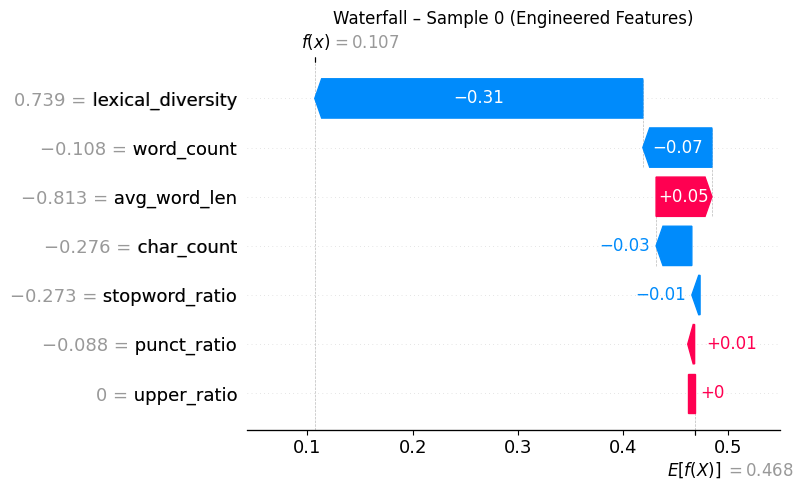

In [ ]:
i = 0
sv_one = shap.Explanation(
    values=sv_cls.values[[i], :],
    base_values=np.array([sv_cls.base_values[i]]),
    data=Xte_slice.iloc[[i]].values,
    feature_names=Xte_slice.columns.tolist()
)
plt.figure(figsize=(7.5,6))
shap.plots.waterfall(sv_one[0], max_display=20, show=False)
plt.title(f"Waterfall – Sample {i} (Engineered Features)")
plt.tight_layout(); plt.show()


In [ ]:
i = 0
proba = float(model.predict(X_test_scaled.iloc[[i]])[0])
pred  = int(proba >= 0.5)  # 1=AI if that’s your mapping
print(f"Row {i}: P(AI)={proba:.3f}, Predicted class={pred}")


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 102ms/step
Row 0: P(AI)=0.107, Predicted class=0


/tmp/ipython-input-2393953742.py:2: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  proba = float(model.predict(X_test_scaled.iloc[[i]])[0])


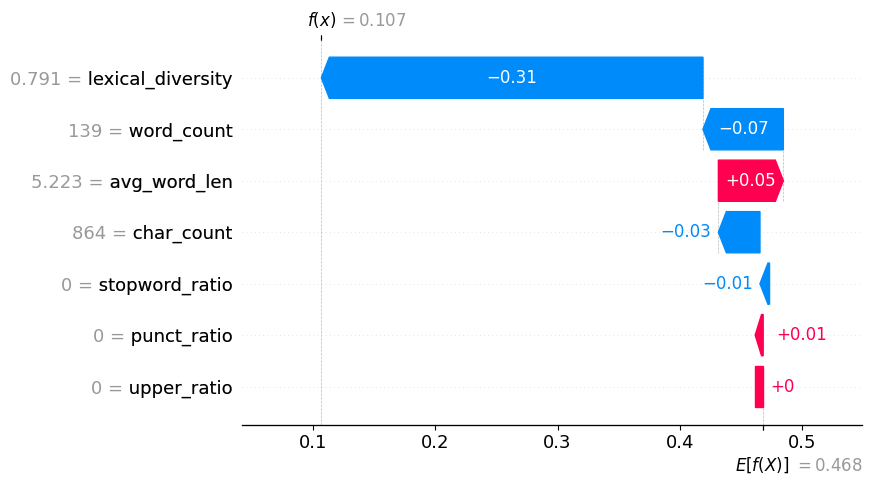

In [ ]:
orig_row = X_test.iloc[[i]]  # unscaled engineered features
sv_pretty = shap.Explanation(
    values=sv_cls.values[[i], :],
    base_values=np.array([sv_cls.base_values[i]]),
    data=orig_row.values,
    feature_names=orig_row.columns.tolist()
)
shap.plots.waterfall(sv_pretty[0], max_display=20)


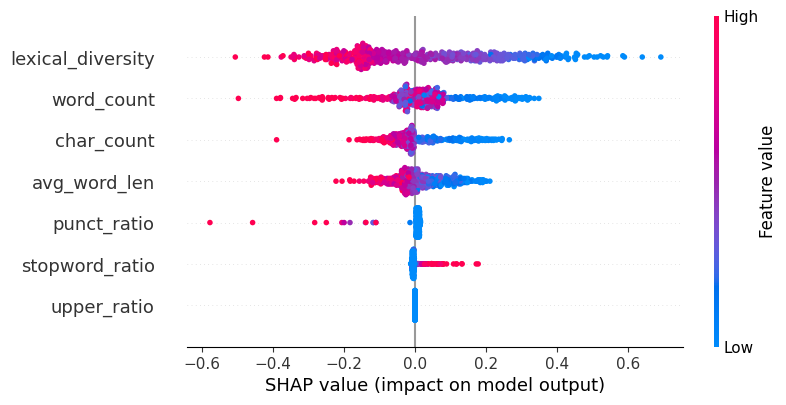

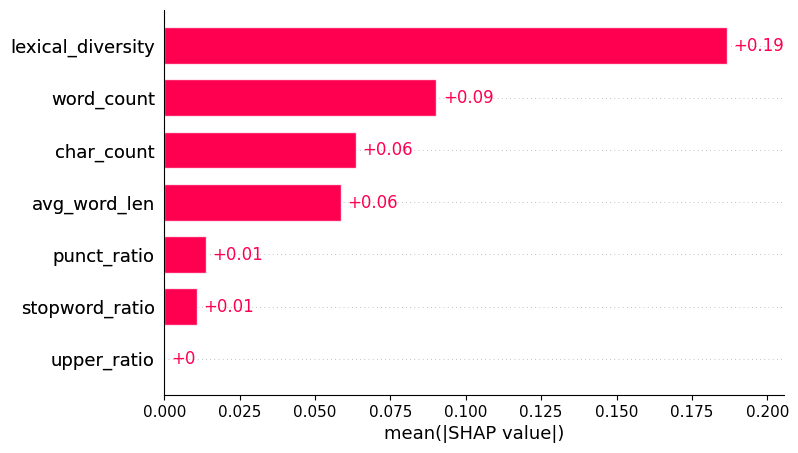

In [ ]:
shap.plots.beeswarm(sv_cls, max_display=20)
shap.plots.bar(sv_cls, max_display=20)   # mean |SHAP|


In [ ]:
# Normalize column names to avoid hidden spaces/case issues
df_bataineh.columns = (df_bataineh.columns
                       .str.strip().str.lower().str.replace(r"\s+", "_", regex=True))

print(df_bataineh.columns.tolist())

# Helpful: show likely candidates
candidates = [c for c in df_bataineh.columns
              if any(k in c for k in ["profic", "discip", "major", "dept", "english", "native", "level", "program"])]
print("Possible group columns:", candidates)


['index', 'text', 'label', 'source', 'text_word_count', 'label_cat', 'source_int', 'processed_text', 'word_count', 'char_count', 'avg_word_len', 'upper_ratio', 'punct_ratio', 'stopword_ratio', 'lexical_diversity']
Possible group columns: []


In [ ]:
# assumes X_test (unscaled engineered features), X_test_scaled, and model
proba = model.predict(X_test_scaled).ravel()  # use [:,1] if softmax

bins_lex = pd.qcut(X_test['lexical_diversity'], 3, labels=['low','mid','high'])
bins_wc  = pd.qcut(X_test['word_count'],        3, labels=['short','medium','long'])

pd.DataFrame({'lex': bins_lex, 'wc': bins_wc, 'p_ai': proba}) \
  .groupby(['lex','wc']).p_ai.mean().unstack()


63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


/tmp/ipython-input-3611868206.py:8: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby(['lex','wc']).p_ai.mean().unstack()


wc,short,medium,long
lex,,,
low,0.662224,0.803967,0.659367
mid,0.498684,0.466426,0.309920
high,0.585051,0.115477,0.048827


In [ ]:
print("sv_cls.values shape:", sv_cls.values.shape)        # (n_samples, n_features)
print("n features:", len(sv_cls.feature_names))


sv_cls.values shape: (500, 7)
n features: 7
